# Tarea 1: Problemas de Regresión — Daily Demand Forecasting Orders

**Curso:** Aprendizaje Automático — Universidad Autónoma de Occidente  
**Integrantes:** David Alberto Vergara Tabares, Sebastián Giraldo Acosta, Violeta Isabella España Bolaños, Luis Felipe Murillo Matallana, Juan David Velasco

## Introducción

El dataset **Daily Demand Forecasting Orders** (repositorio UCI) contiene 60 días de pedidos de una empresa de logística en Brasil. Cada fila es un día y registra cuántos pedidos llegaron por tipo (urgentes, no urgentes, tipos A, B y C) y por sector (fiscal, control de tráfico y tres sectores bancarios), además de la semana del mes y el día de la semana.

**Objetivo:** predecir el total de pedidos del día, `Target (Total orders)`, con un modelo de regresión lineal.

## Análisis exploratorio de datos (EDA)

En esta sección se cargan los datos, se revisa su calidad y se analiza la relación de cada variable con el Target para decidir qué variables estimadoras usar en el modelo.

# 1. Librerías y configuración



In [1]:
# ---------------------------------------------------------------
# Librerías
# ---------------------------------------------------------------
import numpy as np               # Cálculos numéricos con vectores y matrices (se usará en la Ecuación Normal y el gradiente descendente)
import pandas as pd              # Manejo de tablas de datos (DataFrame): leer el CSV, filtrar, calcular estadísticas
import matplotlib.pyplot as plt  # Librería base para hacer gráficas
import seaborn as sns            # Gráficas estadísticas más completas (heatmap, regplot) construidas sobre matplotlib
from scipy import stats          # Funciones estadísticas (pruebas, z-score); disponible para el análisis de outliers

# ---------------------------------------------------------------
# Semilla
# ---------------------------------------------------------------

SEMILLA = 43
np.random.seed(SEMILLA)


# ---------------------------------------------------------------
# Función de apoyo: ficha técnica del dataset
# ---------------------------------------------------------------
def resumen(df):
    """Ficha técnica por columna: tipo, nulos, valores únicos y un ejemplo."""
    # Construye una tabla donde cada fila es una columna del dataset
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),                  # Tipo de dato: int64 (entero), float64 (decimal), object (texto)
        "no_nulos": df.notna().sum(),                   # Cuántos valores sí tienen dato
        "nulos": df.isna().sum(),                       # Cuántos valores están vacíos (NaN)
        "%_nulos": (df.isna().mean() * 100).round(2),   # Porcentaje de vacíos: si es alto habría que imputar o eliminar
        "valores_unicos": df.nunique(),                 # Cuántos valores distintos hay: pocos indica variable categórica
        "ejemplo": df.iloc[0],                          # Valor de la primera fila, para ver cómo luce el dato
    })


## 2 Carga y revisión de los datos

Se lee el archivo CSV original de UCI (separado por `;`) desde la carpeta `dataset/` y se muestran sus dimensiones, las primeras filas y la ficha técnica de cada columna.


### A. Carga del CSV

In [2]:
RUTA_DATOS = "dataset/Daily_Demand_Forecasting_Orders.csv"  # Ruta relativa al archivo CSV del dataset

df = pd.read_csv(RUTA_DATOS, sep=";")      # Lee el archivo CSV indicando que el separador es punto y coma
df = df.dropna(axis=1, how="all")          # Elimina columnas que estén completamente vacías

# Renombra las dos primeras columnas para acortarlas y corregir el paréntesis sin cerrar
df = df.rename(columns={
    df.columns[0]: "Week of the month",    # Columna 0 -> Semana del mes (1 a 5)
    df.columns[1]: "Day of the week"       # Columna 1 -> Día de la semana (2=Lunes a 6=Viernes)
})

#Pasa a miles (/ 1000) las 4 columnas que venían en unidades enteras para unificar la escala
cols_en_unidades = [
    "Orders from the traffic controller sector",
    "Banking orders (1)",
   "Banking orders (2)",
    "Banking orders (3)",
]
df[cols_en_unidades] = df[cols_en_unidades] / 1000.0  # Ej: 188411 pasa a 188.411 (miles de pedidos)

# Corrige también los 11 registros de Fiscal sector orders que se guardaron en unidades sin punto decimal
mask_fiscal = (df["Non-urgent order"] + df["Urgent order"] + df["Fiscal sector orders"] - df["Target (Total orders)"]).abs() > 1
df.loc[mask_fiscal, "Fiscal sector orders"] = df.loc[mask_fiscal, "Fiscal sector orders"] / 1000.0

print(f"Dimensiones: {df.shape} | Filas duplicadas: {df.duplicated().sum()}")  # Imprime (filas, columnas) y duplicados
display(df.head())                         # Muestra las primeras 5 filas ya en la misma escala de miles
display(resumen(df))                       # Muestra la ficha técnica por columna




Dimensiones: (60, 13) | Filas duplicadas: 0


,Week of the month,Day of the week,Non-urgent order,Urgent order,Order type A,Order type B,Order type C,Fiscal sector orders,Orders from the traffic controller sector,Banking orders (1),Banking orders (2),Banking orders (3),Target (Total orders)
0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65.556,44.914,188.411,14.793,539.577
1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40.419,21.399,89.461,7.679,224.675
2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11.992,3.452,21.305,14.947,129.412
3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49.971,33.703,69.054,18.423,317.120
4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48.534,19.646,16.411,20.257,210.517


,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Week of the month,int64,60,0,0.0,5,1.000
Day of the week,int64,60,0,0.0,5,4.000
Non-urgent order,float64,60,0,0.0,60,316.307
Urgent order,float64,60,0,0.0,60,223.270
Order type A,float64,60,0,0.0,60,61.543
Order type B,float64,60,0,0.0,60,175.586
Order type C,float64,60,0,0.0,60,302.448
Fiscal sector orders,float64,60,0,0.0,48,0.000
Orders from the traffic controller sector,float64,60,0,0.0,60,65.556
Banking orders (1),float64,60,0,0.0,60,44.914


**Resultado:** el dataset tiene **60 filas y 13 columnas** (12 predictoras y el Target), todas numéricas, **sin valores nulos**. `Week of the month` y `Day of the week` son categorías codificadas como números (semana 1–5; día 2 = lunes a 6 = viernes).

### Estadísticas descriptivas

Se usa `df.describe()` para obtener, por cada variable, la **media**, la **desviación estándar**, el **mínimo**, los **cuartiles** (25 %, 50 % = mediana, 75 %) y el **máximo**. La tabla se transpone para que cada variable quede en una fila, y se agrega el **rango** (máximo − mínimo) para comparar las escalas.

In [3]:
# describe() calcula, para cada columna numérica:
#   count -> cantidad de datos         mean -> media (promedio)
#   std   -> desviación estándar       min / max -> valor mínimo y máximo
#   25%, 50%, 75% -> cuartiles (el 50% es la mediana)
# .T transpone la tabla: así cada variable queda en una fila y es más fácil de leer
estadisticas = df.describe().T

# Nueva columna "rango" = máximo - mínimo.
# Sirve para comparar de un vistazo las escalas: una variable con rango 4
# frente a otra con rango 200 000 muestra por qué hay que escalar los datos
estadisticas["rango"] = estadisticas["max"] - estadisticas["min"]

# round(2) redondea a 2 decimales para que la tabla sea legible
display(estadisticas.round(2))

,count,mean,std,min,25%,50%,75%,max,rango
Week of the month,60.0,3.02,1.28,1.00,2.00,3.00,4.00,5.00,4.00
Day of the week,60.0,4.03,1.40,2.00,3.00,4.00,5.00,6.00,4.00
Non-urgent order,60.0,172.55,69.51,43.65,125.35,151.06,194.61,435.30,391.65
Urgent order,60.0,118.92,27.17,77.37,100.89,113.11,132.11,223.27,145.90
Order type A,60.0,52.11,18.83,21.83,39.46,47.17,58.46,118.18,96.35
Order type B,60.0,109.23,50.74,25.12,74.92,99.48,132.17,267.34,242.22
Order type C,60.0,139.53,41.44,74.37,113.63,127.99,160.11,302.45,228.08
Fiscal sector orders,60.0,9.40,23.19,0.00,0.09,1.64,12.52,169.28,169.28
Orders from the traffic controller sector,60.0,44.50,12.20,11.99,34.99,44.31,52.11,71.77,59.78
Banking orders (1),60.0,46.64,45.22,3.45,20.13,32.53,45.12,210.51,207.06


#### Interpretación de las estadísticas descriptivas

**1. Diferencias de amplitud (`rango`) y variabilidad.** Una vez expresadas todas las columnas de pedidos en **miles de órdenes**, se identifican dos grupos con amplitudes muy distintas:

| Grupo | Variables | Rango (`max - min`) y valores típicos |
|---|---|---|
| Calendario (discretas) | `Week of the month`, `Day of the week` | Rango de **4.00** (valores de 1 a 6) |
| Volumen de pedidos (en miles) | Resto de predictoras y `Target` | Rango desde **59.78** (`Traffic controller`) hasta **391.65** (`Non-urgent order`) y **487.04** (`Target`) |

`Non-urgent order` presenta una media de **172.56** mil pedidos (con desviación estándar de **69.51**), lo que representa por sí sola cerca del **60 %** del volumen diario total (`Target` promedio de **300.87**), siendo el componente de mayor peso dentro de la operación. Por su parte, variables como `Day of the week` tienen una desviación estándar de apenas **1.40**, diferencia de magnitudes que se tendrá en cuenta en la etapa de escalado.

**2. Asimetría positiva y colas largas a la derecha.** Cuando la **media (`mean`)** supera a la **mediana (`50%`)** y el **máximo (`max`)** se aleja del tercer cuartil (`75%`), existen días pico que desplazan el promedio hacia arriba:

- **`Fiscal sector orders`:** tiene mediana de **1.64** mil pedidos y el 75 % de los días no supera **12.52**, pero su media sube a **9.40** (desviación de **23.19**) debido a un máximo de **169.28** mil pedidos.
- **`Banking orders (1)`:** su mediana es **32.53** mil y su percentil 75 % es **45.12**, pero alcanza un máximo de **210.51** mil pedidos (media de **46.64**).
- **`Non-urgent order`:** su mediana es **151.06** mil y el 75 % de los días está por debajo de **194.61**, llegando hasta un máximo de **435.30** mil pedidos.

**3. Comportamiento de la variable objetivo (`Target (Total orders)`).** Oscila entre un mínimo de **129.41** y un máximo de **616.45** mil pedidos diarios, con una media de **300.87** superior a su mediana de **288.03**, mostrando una cola hacia valores altos que se examina en las siguientes subsecciones.

###  Celda de histogramas iniciales:

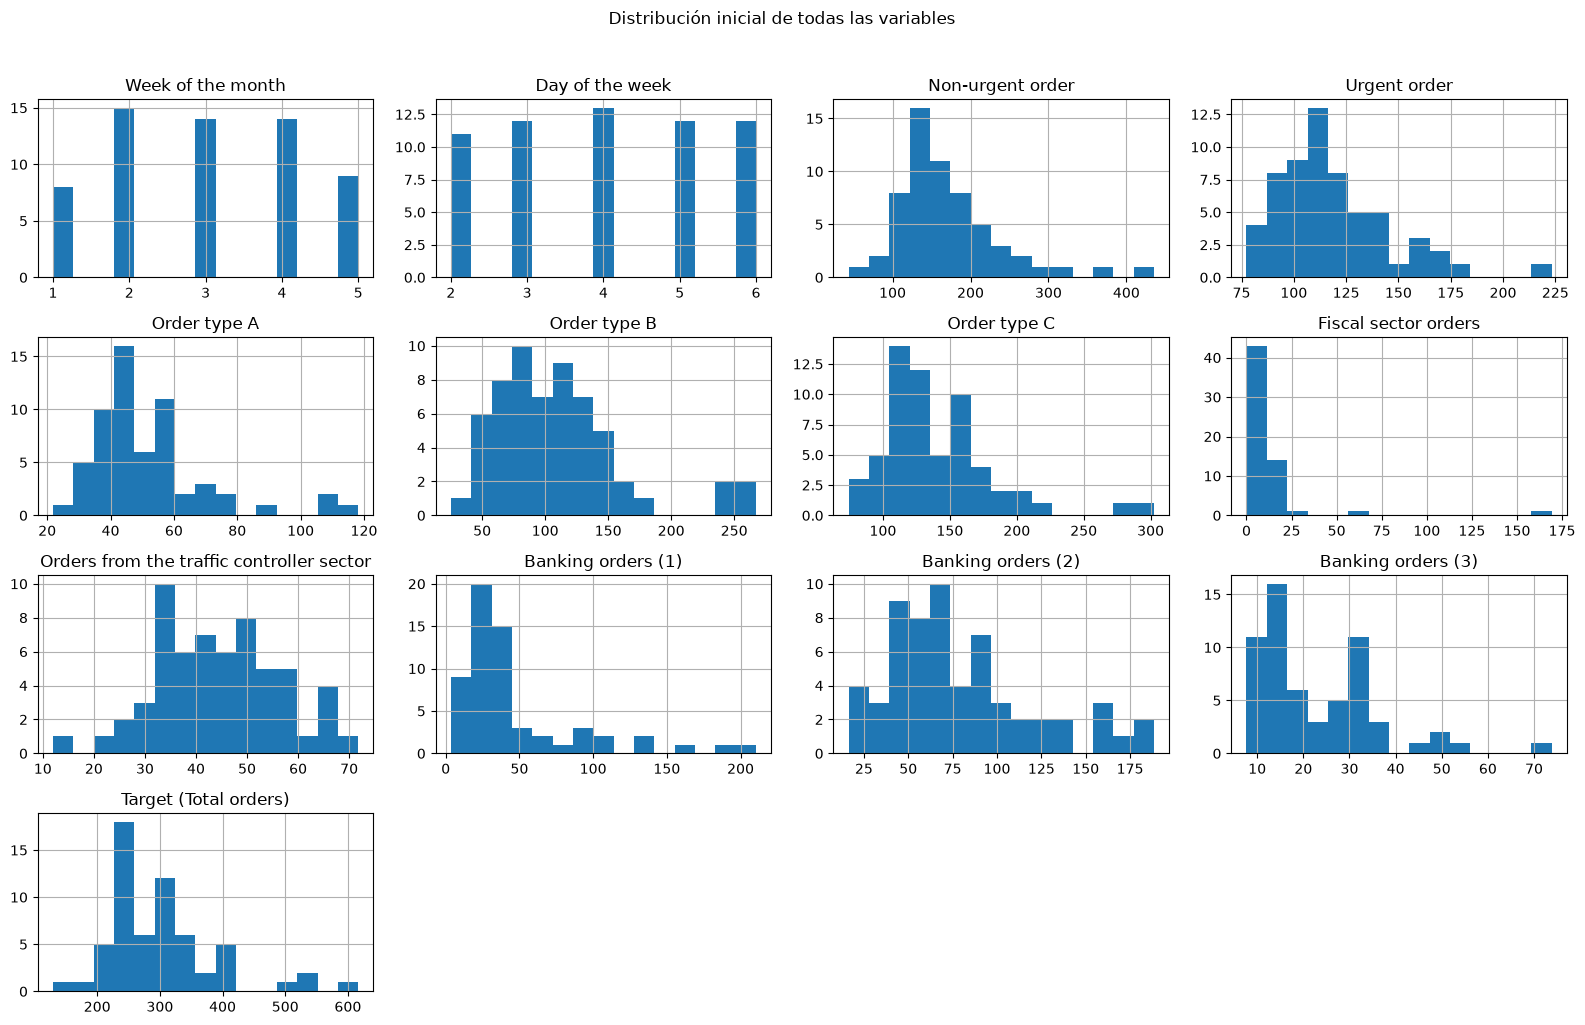

In [4]:
df.hist(bins=15, figsize=(16, 10))                                    # Dibuja un histograma de 15 barras para cada columna numérica
plt.suptitle("Distribución inicial de todas las variables", y=1.02)   # Agrega un título general arriba de toda la figura
plt.tight_layout()                                                    # Ajusta automáticamente los espacios para que no se encimen los textos
plt.show()                                                            # Renderiza la gráfica en pantalla

## B. División estratificada Entrenamiento / Validación

Para evitar la fuga de información (*data leakage*), dividimos el conjunto de datos en **entrenamiento (80 %)** y **validación (20 %)** antes de realizar transformaciones o tomar decisiones profundas. Como el dataset es pequeño (60 días) y `Non-urgent order` es el predictor con mayor peso sobre la demanda total, estratificamos por cuartiles de esta variable para asegurar que ambos subconjuntos mantengan la misma distribución de días de baja, media y alta demanda.

In [5]:
from sklearn.model_selection import train_test_split  # Función para dividir datos en entrenamiento y validación

# Crea 4 categorías (cuartiles 1, 2, 3, 4) según el volumen de pedidos no urgentes para poder estratificar
df["estrato_demanda"] = pd.qcut(df["Non-urgent order"], q=4, labels=[1, 2, 3, 4])

# Divide el dataset: 80% entrenamiento (48 filas) y 20% validación (12 filas), manteniendo la proporción de cada estrato
train_df, test_df = train_test_split(
    df,
    test_size=0.20,                   # Reserva el 20% de los datos para validación
    stratify=df["estrato_demanda"],   # Obliga a repartir igual porcentaje de cada estrato en train y test
    random_state=SEMILLA              # Usa nuestra semilla (43) para que la división sea siempre la misma
)

# Verifica en una tabla que las proporciones (%) de cada estrato quedaron idénticas en total, train y test
comparar_estratos = pd.DataFrame({
    "Total (%)": df["estrato_demanda"].value_counts(normalize=True) * 100,       # % en los 60 días
    "Train (%)": train_df["estrato_demanda"].value_counts(normalize=True) * 100, # % en los 48 días de entrenamiento
    "Test (%)":  test_df["estrato_demanda"].value_counts(normalize=True) * 100,  # % en los 12 días de validación
}).sort_index()
display(comparar_estratos.round(1))   # Muestra la tabla comparativa redondeada a 1 decimal

# Elimina la columna temporal "estrato_demanda" de los tres DataFrames porque solo se usó para partir los datos
df = df.drop(columns="estrato_demanda")
train_df = train_df.drop(columns="estrato_demanda")
test_df = test_df.drop(columns="estrato_demanda")

eda = train_df.copy()  # Crea una copia solo del entrenamiento para hacer todo el EDA sin tocar validación


,Total (%),Train (%),Test (%)
estrato_demanda,,,
1,25.0,25.0,25.0
2,25.0,25.0,25.0
3,25.0,25.0,25.0
4,25.0,25.0,25.0


### C. La variable objetivo: asimetría y transformaciones

Analizamos la distribución de `Target (Total orders)` sobre el conjunto de entrenamiento (`eda`). Los modelos de regresión lineal funcionan mejor cuando los errores son aproximadamente simétricos y de varianza constante; transformar una variable asimétrica con logaritmo natural $\log(1 + y)$ comprime la cola derecha y acerca la distribución a una normal.

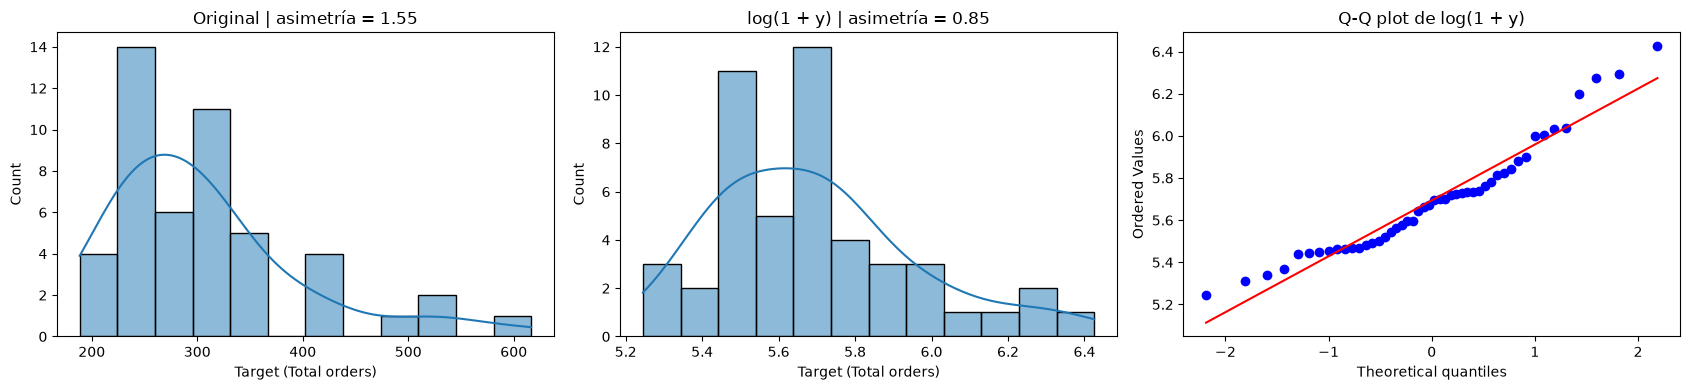

In [6]:
y_eda = eda["Target (Total orders)"]  # Extrae la variable objetivo únicamente del conjunto de entrenamiento

fig, axes = plt.subplots(1, 3, figsize=(17, 4))  # Crea una figura con 1 fila y 3 subgráficas lado a lado

# 1. Histograma y curva de densidad (KDE) de la variable objetivo original
sns.histplot(y_eda, kde=True, bins=12, ax=axes[0])                          # Grafica barras de frecuencia y curva suave
axes[0].set_title(f"Original | asimetría = {y_eda.skew():.2f}")             # Muestra el coeficiente de asimetría original

# 2. Histograma y curva KDE aplicando logaritmo natural log(1 + y)
sns.histplot(np.log1p(y_eda), kde=True, bins=12, ax=axes[1])                # np.log1p calcula log(1 + y) comprimiendo valores altos
axes[1].set_title(f"log(1 + y) | asimetría = {np.log1p(y_eda).skew():.2f}") # Muestra cómo se reduce la asimetría

# 3. Gráfico Q-Q plot de log(1 + y) contra una distribución normal
stats.probplot(np.log1p(y_eda), dist="norm", plot=axes[2])                  # Compara cuantiles reales (puntos) con la recta normal (roja)
axes[2].set_title("Q-Q plot de log(1 + y)")                                 # Título de la tercera gráfica

plt.tight_layout()  # Ajusta márgenes automáticamente
plt.show()          # Muestra las 3 gráficas

In [7]:
from sklearn.preprocessing import PowerTransformer  # Transformador que busca el exponente óptimo para simetrizar datos

# Lista de variables predictoras numéricas de pedidos (excluyendo calendario y Target)
cols_predictoras = [c for c in eda.columns if c not in ["Week of the month", "Day of the week", "Target (Total orders)"]]

# Construye una tabla comparando la asimetría antes y después de transformar
tabla_asimetria = pd.DataFrame({
    "Original": eda[cols_predictoras].skew(),                        # Asimetría de los datos originales en entrenamiento
    "log1p": np.log1p(eda[cols_predictoras]).skew(),                 # Asimetría tras aplicar log(1 + x)
    "Yeo-Johnson": pd.DataFrame(                                     # Asimetría tras ajustar PowerTransformer
        PowerTransformer(method="yeo-johnson").fit_transform(eda[cols_predictoras]),
        columns=cols_predictoras
    ).skew(),
})

print("Asimetría (skewness) en las variables predictoras antes y después de transformar:")
display(tabla_asimetria.round(2))  # Muestra la tabla redondeada a 2 decimales

Asimetría (skewness) en las variables predictoras antes y después de transformar:


,Original,log1p,Yeo-Johnson
Non-urgent order,1.78,0.80,0.06
Urgent order,1.39,0.70,0.03
Order type A,1.95,0.97,0.04
Order type B,1.47,0.35,0.01
Order type C,1.95,0.82,-0.04
Fiscal sector orders,5.35,0.50,0.14
Orders from the traffic controller sector,0.45,0.02,0.00
Banking orders (1),2.18,0.50,0.00
Banking orders (2),1.12,0.01,0.00
Banking orders (3),1.43,0.43,0.11


#### Interpretación de la asimetría y las transformaciones

1. **En la variable objetivo (`Target`):** la distribución original presenta una asimetría positiva pronunciada (**1.55**) debido a los días con picos de demanda superiores a 450 mil pedidos. Al aplicar `log(1 + y)`, la asimetría se reduce a **0.85**: mejora, pero sigue siendo una asimetría positiva moderada, y el **Q-Q plot** permite ver cuánto se acercan los puntos a la recta teórica normal.
2. **En las variables predictoras:**
   - La mayoría de las variables de volumen presentan asimetría positiva alta (`Fiscal sector orders` = **5.35**, `Banking orders (1)` = **2.18**, `Order type C` = **1.95**, `Non-urgent order` = **1.78** y `Banking orders (3)` = **1.43**). Con la transformación `log1p`, su asimetría disminuye (**0.50**, **0.50**, **0.82**, **0.80** y **0.43**, respectivamente), y con **Yeo-Johnson** queda casi en cero en todas las predictoras (entre **-0.04** y **0.14**).
   - Por el contrario, `Orders from the traffic controller sector` es casi simétrica en su escala original (**0.45**) y no necesita transformación. Por ello, la transformación logarítmica solo se aplicaría a las variables sesgadas.

### D. Valores atípicos (*outliers*)

Evaluamos la presencia de valores atípicos en el conjunto de entrenamiento (`eda`) mediante dos criterios estadísticos clásicos:
- **Rango intercuartílico (Tukey):** un dato es atípico si cae fuera de $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$, donde $\text{IQR} = Q_3 - Q_1$.
- **Puntaje $z$ (*z-score*):** un dato es atípico si se aleja más de 3 desviaciones estándar de la media ($|z| > 3$).

Comparamos además cuántos registros siguen marcándose como atípicos después de aplicar la transformación `log1p` en las variables con asimetría.

Cantidad y porcentaje de registros marcados como atípicos en entrenamiento:


,IQR_cant,IQR_original (%),z>3_original (%),IQR_tras_log (%)
Week of the month,0,0.00,0.00,NaN
Day of the week,0,0.00,0.00,NaN
Non-urgent order,4,8.33,2.08,4.17
Urgent order,2,4.17,2.08,2.08
Order type A,3,6.25,4.17,4.17
Order type B,4,8.33,0.00,0.00
Order type C,2,4.17,4.17,4.17
Fiscal sector orders,2,4.17,2.08,0.00
Orders from the traffic controller sector,0,0.00,0.00,NaN
Banking orders (1),8,16.67,4.17,6.25


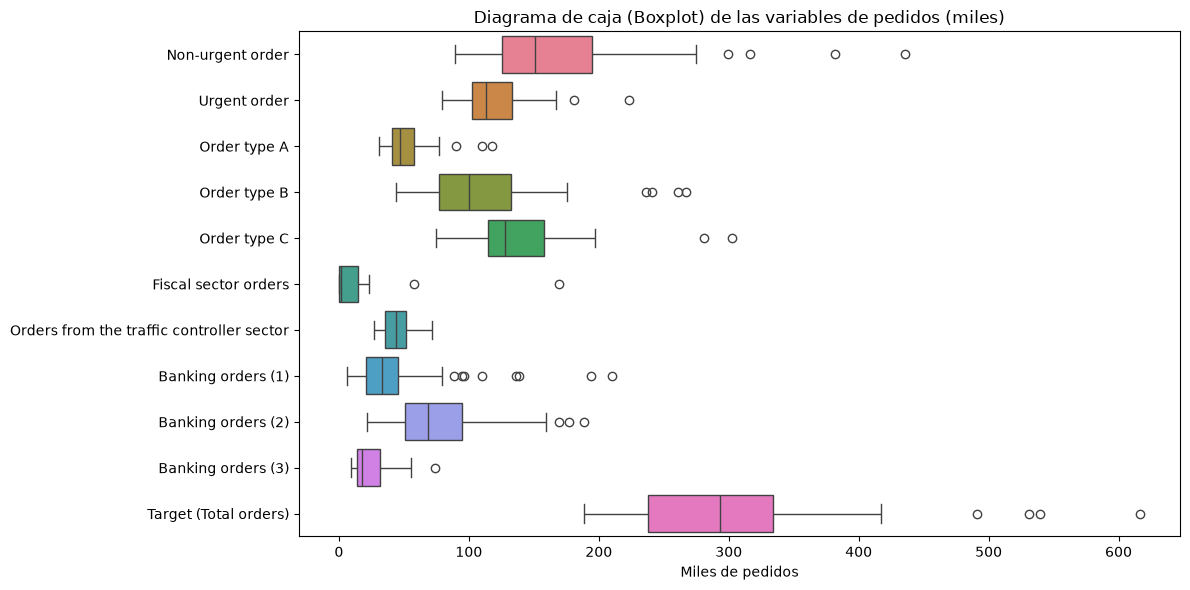

In [8]:
def outliers_iqr(serie, k=1.5):
    """Devuelve True para cada registro que quede fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]."""
    q1, q3 = serie.quantile([0.25, 0.75])            # Obtiene el primer cuartil (25%) y el tercer cuartil (75%)
    iqr = q3 - q1                                    # Calcula el rango intercuartílico (ancho de la caja central)
    return (serie < q1 - k * iqr) | (serie > q3 + k * iqr)  # Marca como True los valores fuera de los bigotes

num_cols = eda.select_dtypes("number").columns       # Selecciona todas las columnas numéricas de entrenamiento

# Variables que presentaron asimetría moderada o alta en la sección anterior
sesgadas = [
    "Non-urgent order", "Urgent order", "Order type A", "Order type B",
    "Order type C", "Fiscal sector orders", "Banking orders (1)",
    "Banking orders (2)", "Banking orders (3)", "Target (Total orders)"
]

# Construye la tabla comparativa de porcentaje de outliers según cada criterio
tabla_out = pd.DataFrame({
    "IQR_cant": [outliers_iqr(eda[c]).sum() for c in num_cols],                                 # Cantidad de días atípicos por IQR
    "IQR_original (%)": [outliers_iqr(eda[c]).mean() * 100 for c in num_cols],                  # % de filas atípicas por IQR original
    "z>3_original (%)": [(np.abs(stats.zscore(eda[c])) > 3).mean() * 100 for c in num_cols],    # % de filas con puntaje |z| > 3
    "IQR_tras_log (%)": [                                                                       # % de filas atípicas por IQR tras aplicar log1p
        outliers_iqr(np.log1p(eda[c])).mean() * 100 if c in sesgadas else np.nan
        for c in num_cols
    ],
}, index=num_cols)

print("Cantidad y porcentaje de registros marcados como atípicos en entrenamiento:")
display(tabla_out.round(2))  # Muestra la tabla redondeada a 2 decimales

# Visualización mediante diagramas de caja (Boxplots) de las variables de volumen
cols_volumen = [c for c in num_cols if c not in ["Week of the month", "Day of the week"]]
plt.figure(figsize=(12, 6))                                                  # Define el tamaño de la figura
sns.boxplot(data=eda[cols_volumen], orient="h")                              # Dibuja un boxplot horizontal por variable
plt.title("Diagrama de caja (Boxplot) de las variables de pedidos (miles)")  # Título de la gráfica
plt.xlabel("Miles de pedidos")                                               # Etiqueta del eje X
plt.tight_layout()                                                           # Ajusta márgenes
plt.show()                                                                   # Muestra la gráfica

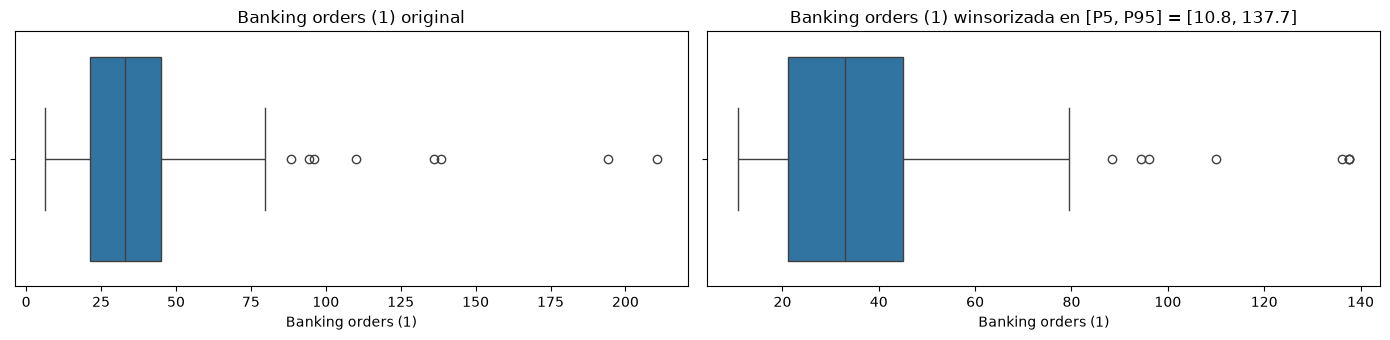

In [9]:
# Calcula los percentiles 5% y 95% de Banking orders (1) en el conjunto de entrenamiento
p05, p95 = eda["Banking orders (1)"].quantile([0.05, 0.95])

# Recorta (winsoriza) los valores extremos dejándolos dentro del intervalo [P5, P95]
banca1_winsor = eda["Banking orders (1)"].clip(lower=p05, upper=p95)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))  # Crea 2 gráficas lado a lado para comparar antes y después

sns.boxplot(x=eda["Banking orders (1)"], ax=axes[0])                                        # Boxplot sin recortar
axes[0].set_title("Banking orders (1) original")                                            # Título izquierda

sns.boxplot(x=banca1_winsor, ax=axes[1])                                                    # Boxplot winsorizado
axes[1].set_title(f"Banking orders (1) winsorizada en [P5, P95] = [{p05:.1f}, {p95:.1f}]")  # Título derecha

plt.tight_layout()  # Ajusta márgenes
plt.show()          # Muestra la comparación

#### Interpretación del análisis de valores atípicos

1. **Diferencia entre criterios (`IQR` vs. `|z| > 3`):** el criterio IQR marca hasta un **16.67 %** de los días en `Banking orders (1)` (8 registros) y un **8.33 %** en `Non-urgent order`, `Order type B` y `Target` (4 registros), mientras que el puntaje $|z| > 3$ solo marca entre **2.08 % y 4.17 %** (1 o 2 registros).
2. **Efecto de la transformación logarítmica:** gran parte de los supuestos *outliers* por IQR son en realidad la cola derecha natural de distribuciones asimétricas. Al aplicar `log1p`, los valores atípicos desaparecen por completo (**0.00 %**) en `Fiscal sector orders`, `Order type B`, `Banking orders (2)` y `Banking orders (3)`, y se reducen en `Banking orders (1)` (de 16.67 % a **6.25 %**) y en `Target` (de 8.33 % a **2.08 %**).
3. **Decisión de preparación de datos:** dado que el conjunto de entrenamiento cuenta únicamente con **48 días** y los valores altos corresponden a picos legítimos de actividad logística y bancaria, no se eliminan filas; en su lugar, se emplearán transformaciones (`log1p`) y escalado en el preprocesamiento.


# 3. MANEJO DE LOS DATOS

## A. Exploración de los datos (comportamiento temporal y por categorías)

A diferencia de problemas espaciales, en logística la estructura del negocio está guiada por el calendario operativo: el **día de la semana** (`Day of the week`, donde 2 = lunes a 6 = viernes) y la **semana del mes** (`Week of the month`, de 1 a 5). Analizamos en el conjunto de entrenamiento (`eda`) cómo varía el total de pedidos según estas dos dimensiones.

Demanda por día de la semana (2=Lunes ... 6=Viernes):


,count,mean,median
Day of the week,,,
2,8,402.94,383.89
3,10,318.82,288.03
4,11,279.28,244.24
5,10,281.94,284.00
6,9,271.67,248.96



Demanda por semana del mes (1 a 5):


,count,mean,median
Week of the month,,,
1,6,336.28,297.87
2,13,258.96,238.83
3,12,321.25,303.32
4,10,303.92,288.14
5,7,352.84,306.36


/tmp/ipykernel_45836/255490310.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=eda, x="Day of the week", y="Target (Total orders)", ax=axes[0], palette="Blues_r")
/tmp/ipykernel_45836/255490310.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=eda, x="Week of the month", y="Target (Total orders)", ax=axes[1], palette="Greens")


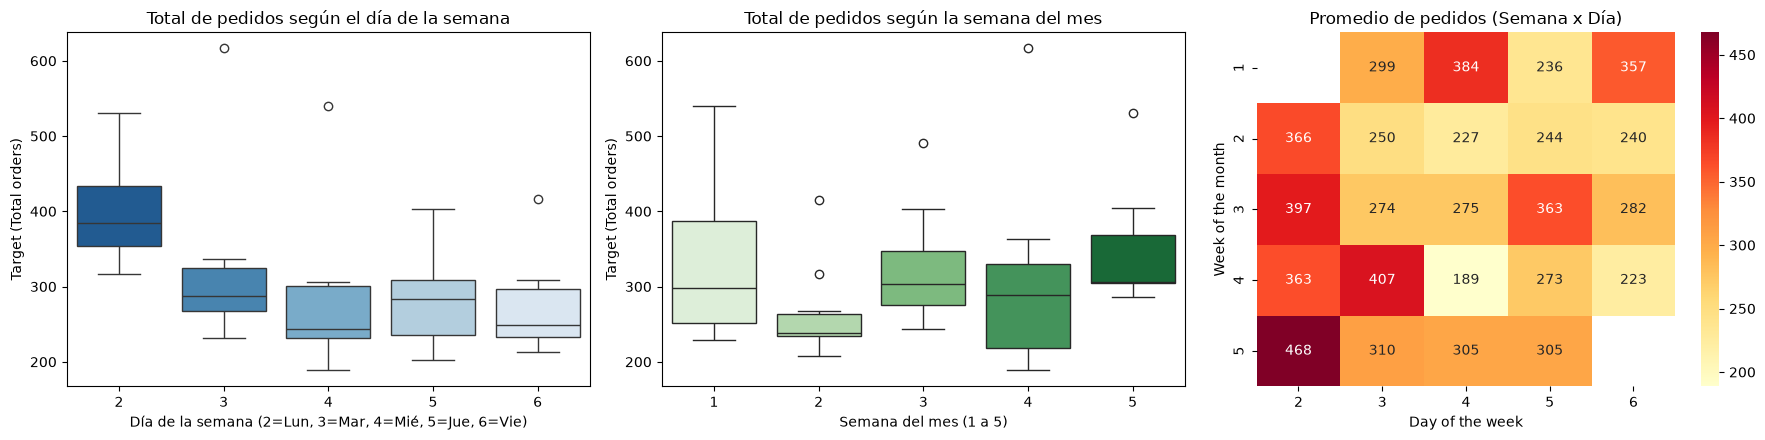

In [10]:
# Resumen estadístico del Target agrupado por día de la semana y por semana del mes
print("Demanda por día de la semana (2=Lunes ... 6=Viernes):")
display(eda.groupby("Day of the week")["Target (Total orders)"].agg(["count", "mean", "median"]).round(2))

print("\nDemanda por semana del mes (1 a 5):")
display(eda.groupby("Week of the month")["Target (Total orders)"].agg(["count", "mean", "median"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))  # Crea una figura con 3 gráficas en una fila

# 1. Boxplot del Target según el día de la semana
sns.boxplot(data=eda, x="Day of the week", y="Target (Total orders)", ax=axes[0], palette="Blues_r")
axes[0].set_title("Total de pedidos según el día de la semana")   # Título gráfica 1
axes[0].set_xlabel("Día de la semana (2=Lun, 3=Mar, 4=Mié, 5=Jue, 6=Vie)")

# 2. Boxplot del Target según la semana del mes
sns.boxplot(data=eda, x="Week of the month", y="Target (Total orders)", ax=axes[1], palette="Greens")
axes[1].set_title("Total de pedidos según la semana del mes")     # Título gráfica 2
axes[1].set_xlabel("Semana del mes (1 a 5)")

# 3. Tabla pivote (mapa de calor) combinando Semana del mes vs. Día de la semana
pivote = eda.pivot_table(index="Week of the month", columns="Day of the week", values="Target (Total orders)", aggfunc="mean")
sns.heatmap(pivote, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[2])  # Dibuja el promedio de pedidos en cada cruce
axes[2].set_title("Promedio de pedidos (Semana x Día)")                # Título gráfica 3

plt.tight_layout()  # Ajusta márgenes automáticamente
plt.show()          # Muestra las 3 gráficas

## B. Diagramas de dispersión

Graficamos cada variable predictora de volumen contra `Target (Total orders)` en el conjunto de entrenamiento (`eda`), incluyendo la recta de ajuste lineal, para evaluar visualmente la forma de la relación, el grado de dispersión de los puntos y la influencia de los días pico.

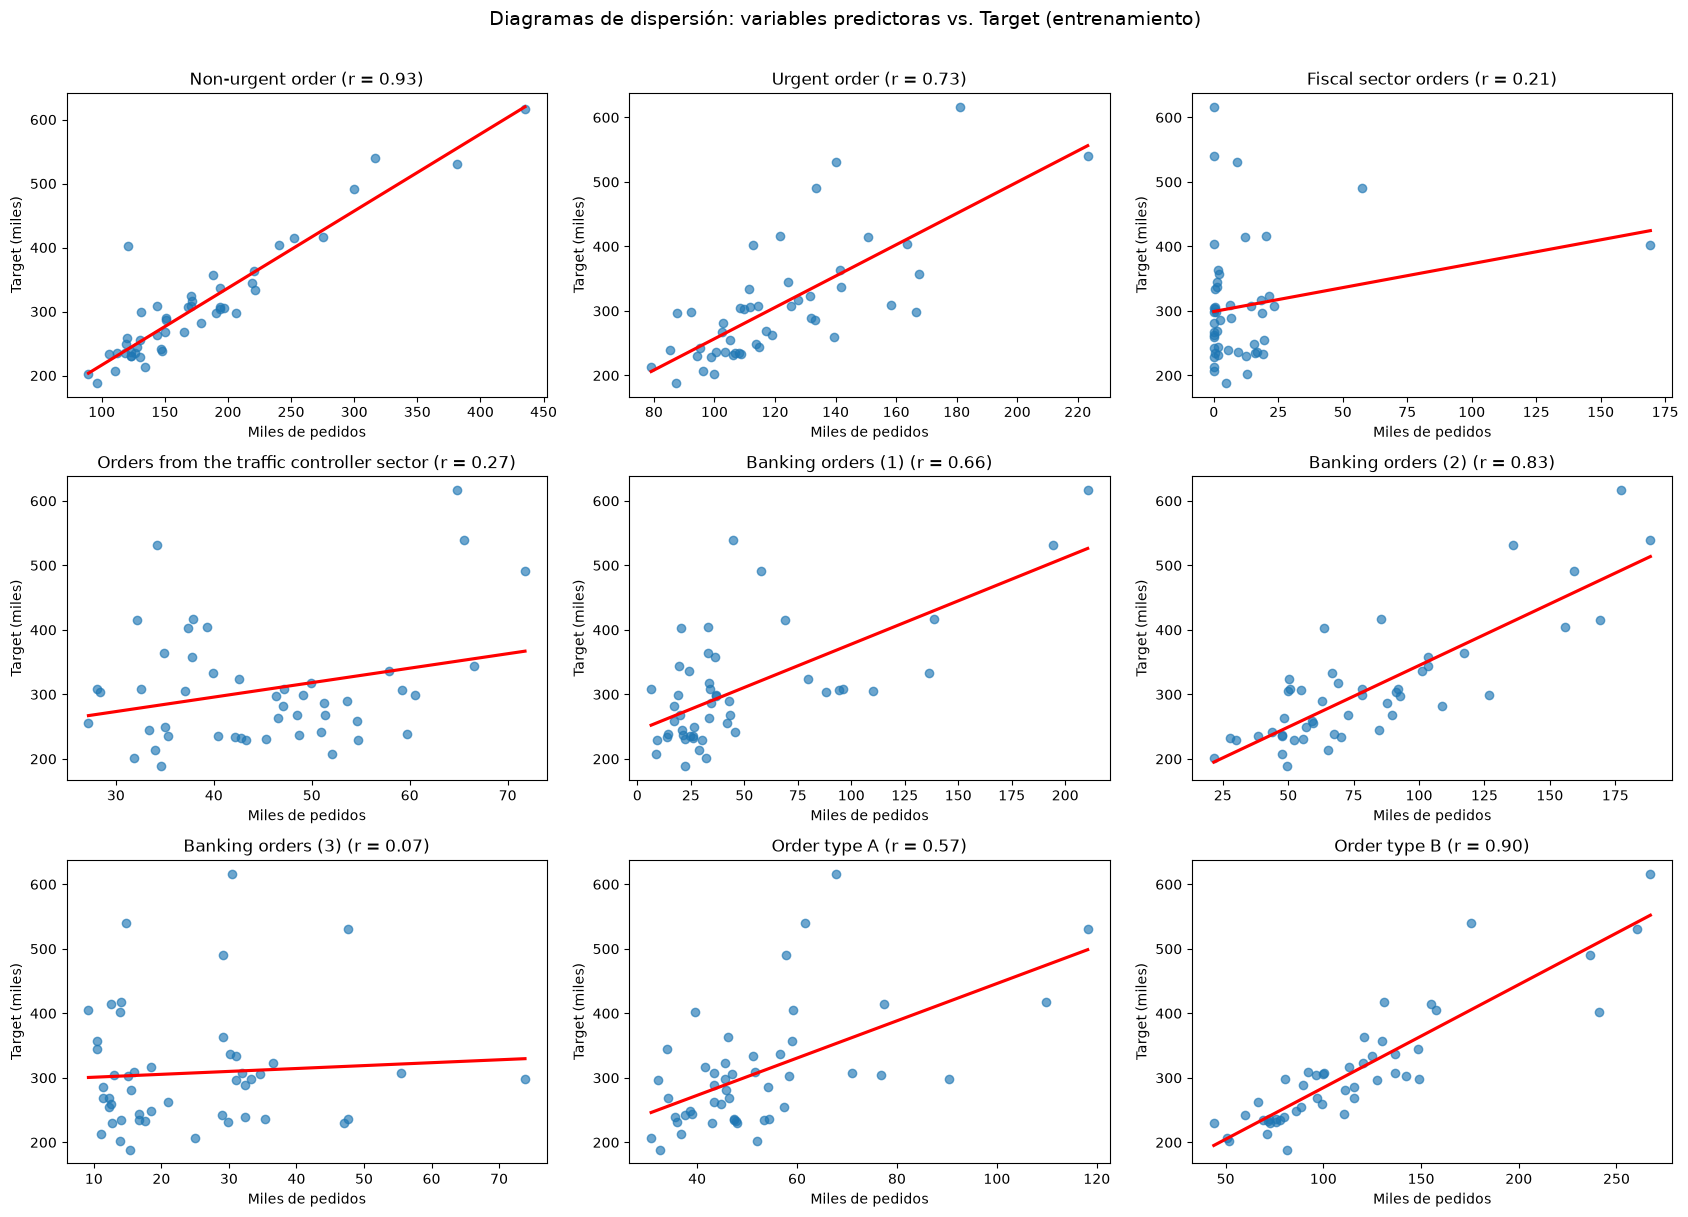

In [11]:
objetivo = "Target (Total orders)"  # Variable objetivo en el eje Y

# Variables predictoras de volumen a graficar en el eje X
variables_disp = [
    "Non-urgent order",
    "Urgent order",
    "Fiscal sector orders",
    "Orders from the traffic controller sector",
    "Banking orders (1)",
    "Banking orders (2)",
    "Banking orders (3)",
    "Order type A",
    "Order type B",
]

fig, axes = plt.subplots(3, 3, figsize=(17, 12))  # Crea una cuadrícula de 3 filas x 3 columnas

# Recorre cada espacio de la cuadrícula y dibuja el diagrama de dispersión con su recta lineal
for ax, variable in zip(axes.flatten(), variables_disp):
    sns.regplot(
        data=eda,                         # Usa únicamente el conjunto de entrenamiento
        x=variable,                       # Variable predictora en el eje X
        y=objetivo,                       # Total de pedidos en el eje Y
        ax=ax,                            # Subgráfica actual
        scatter_kws={"alpha": 0.65},      # Transparencia de los puntos para apreciar acumulación
        line_kws={"color": "red"},        # Recta de tendencia lineal en color rojo
        ci=None                           # Desactiva la sombra del intervalo de confianza
    )
    corr_val = eda[variable].corr(eda[objetivo])      # Calcula la correlación de Pearson en entrenamiento
    ax.set_title(f"{variable} (r = {corr_val:.2f})")  # Muestra nombre y correlación en el título
    ax.set_xlabel("Miles de pedidos")                 # Etiqueta del eje X
    ax.set_ylabel("Target (miles)")                   # Etiqueta del eje Y

plt.suptitle("Diagramas de dispersión: variables predictoras vs. Target (entrenamiento)", y=1.01, fontsize=14)
plt.tight_layout()  # Ajusta los espacios entre subgráficas
plt.show()          # Muestra la figura completa

#### Interpretación de los diagramas de dispersión

- **Relación lineal fuerte y definida:** `Non-urgent order` ($r = 0.93$), `Order type B` ($r = 0.90$), `Banking orders (2)` ($r = 0.83$) y `Urgent order` ($r = 0.73$) muestran una nube de puntos ascendente muy alineada con la recta roja.
- **Relación moderada con apalancamiento en días pico:** `Banking orders (1)` ($r = 0.66$) y `Order type A` ($r = 0.57$) concentran la mayoría de los días en valores bajos, mientras los días de alta demanda inclinan la pendiente positivamente.
- **Relación débil o casi nula:** `Orders from the traffic controller sector` ($r = 0.27$), `Fiscal sector orders` ($r = 0.21$) y `Banking orders (3)` ($r = 0.07$) muestran alta dispersión alrededor de una recta casi horizontal, aportando poca capacidad predictiva individual.

## C. Diagramas de correlación y multicolinealidad (VIF)

Comparamos dos matrices de correlación sobre el conjunto de entrenamiento (`eda`):
- **Pearson:** mide la relación **lineal** entre pares de variables y es sensible a valores extremos.
- **Spearman:** evalúa la relación **monótona** basada en rangos y es robusta frente a valores atípicos.

Posteriormente, calculamos el **Factor de Inflación de la Varianza (VIF)**:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el coeficiente de determinación al predecir la variable $j$ con el resto de predictoras. Un $\text{VIF} > 5$ alerta sobre colinealidad moderada, un $\text{VIF} > 10$ indica multicolinealidad severa y $\text{VIF} = \infty$ revela que una variable es combinación lineal exacta de otras.

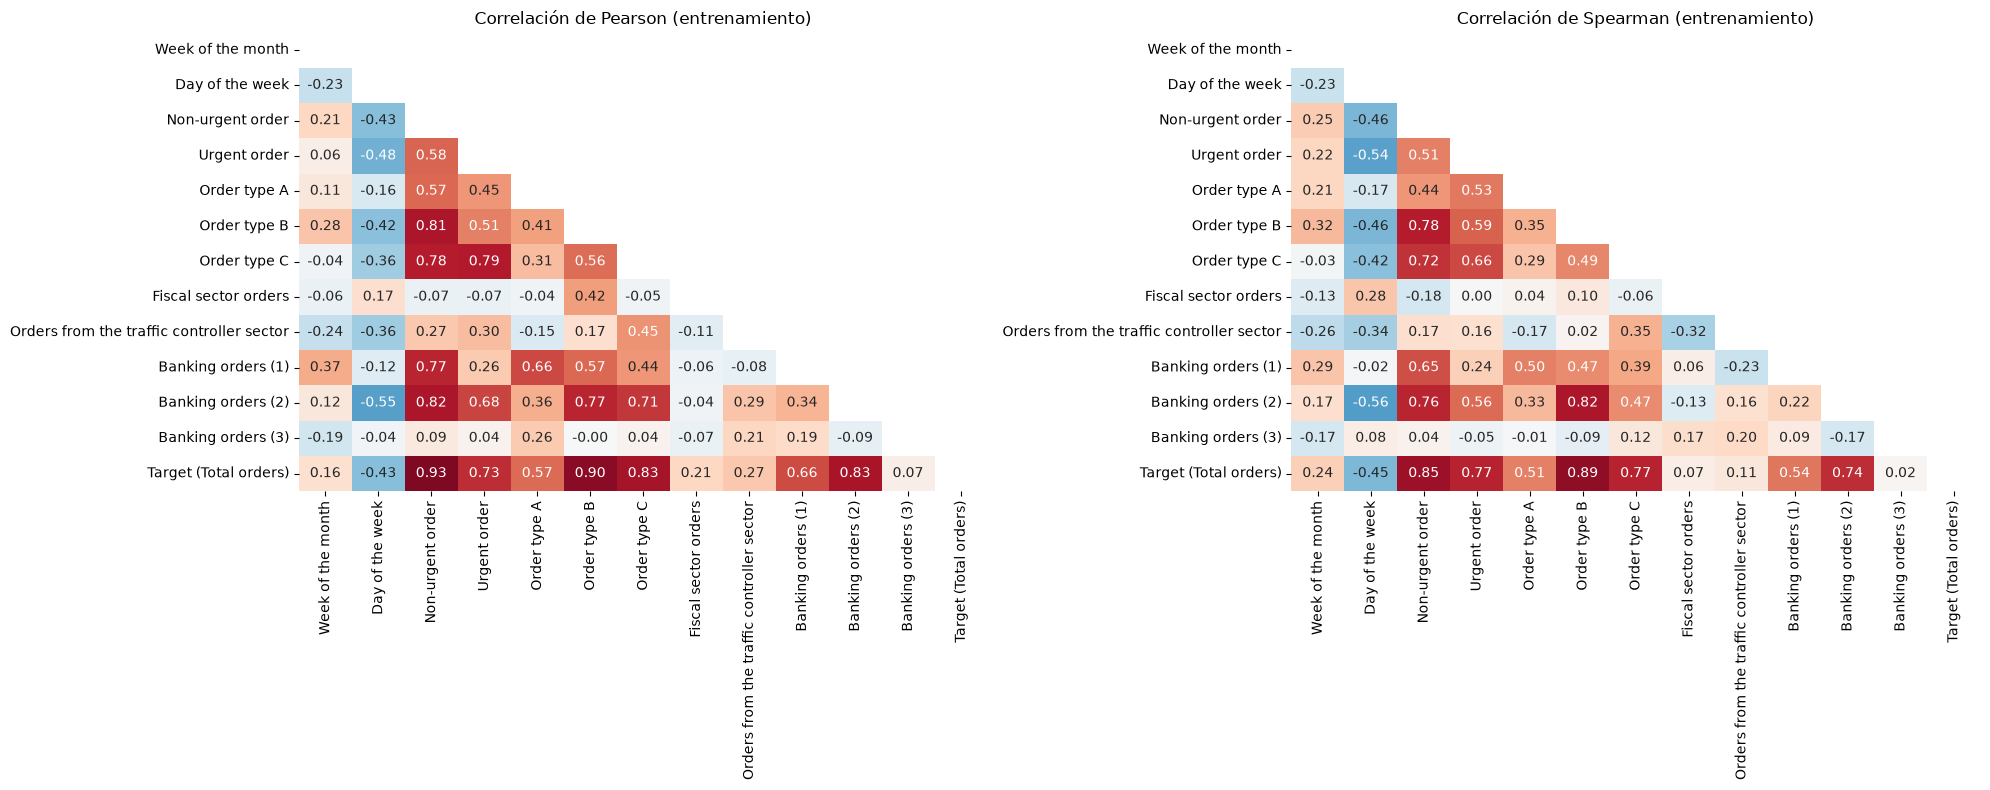

,Pearson,Spearman
Non-urgent order,0.93,0.85
Order type B,0.90,0.89
Order type C,0.83,0.77
Banking orders (2),0.83,0.74
Urgent order,0.73,0.77
Banking orders (1),0.66,0.54
Order type A,0.57,0.51
Orders from the traffic controller sector,0.27,0.11
Fiscal sector orders,0.21,0.07
Week of the month,0.16,0.24


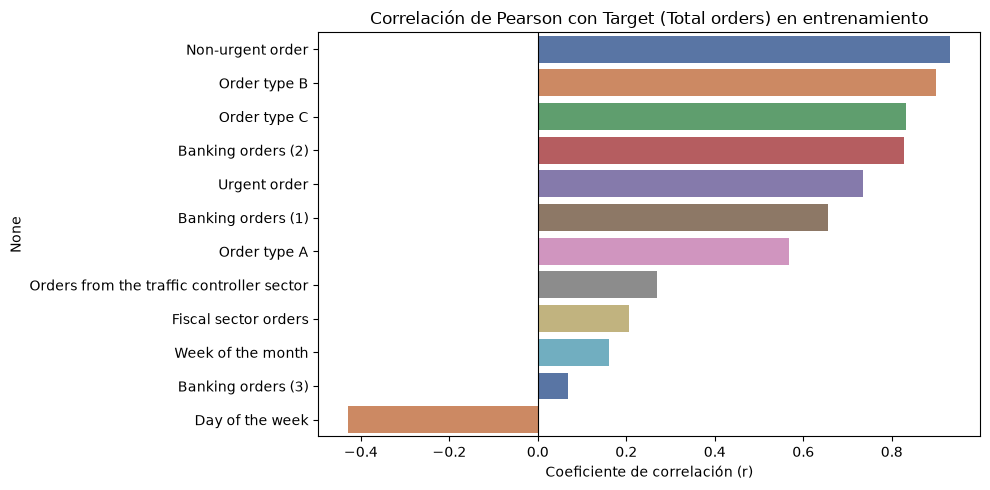

In [12]:
objetivo = "Target (Total orders)"  # Nombre de la variable objetivo

# 1. Mapas de calor comparando Pearson (lineal) y Spearman (por rangos)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))  # Crea 2 subgráficas lado a lado
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    matriz_corr = eda.corr(method=metodo, numeric_only=True)        # Calcula la matriz de correlación según el método
    mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))        # Oculta el triángulo superior repetido
    sns.heatmap(
        matriz_corr, mask=mascara, annot=True, fmt=".2f",           # Muestra los valores con 2 decimales
        cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False           # Escala de color de -1 (azul) a +1 (rojo)
    )
    ax.set_title(f"Correlación de {metodo.capitalize()} (entrenamiento)")

plt.tight_layout()  # Ajusta márgenes
plt.show()          # Muestra los dos mapas de calor

# 2. Tabla y gráfica de barras de correlación de cada predictora frente al Target
corr_target = pd.DataFrame({
    "Pearson": eda.corr(method="pearson")[objetivo],                # Correlación lineal con el Target
    "Spearman": eda.corr(method="spearman")[objetivo],              # Correlación por rangos con el Target
}).drop(objetivo).sort_values(by="Pearson", ascending=False)        # Excluye el propio Target y ordena de mayor a menor

display(corr_target.round(2))  # Muestra la tabla comparativa

plt.figure(figsize=(10, 5))
sns.barplot(
    x=corr_target["Pearson"].values,
    y=corr_target.index,
    hue=corr_target.index,   # Asigna hue para evitar advertencias de versión en seaborn
    legend=False,
    palette="deep"
)
plt.title("Correlación de Pearson con Target (Total orders) en entrenamiento")
plt.xlabel("Coeficiente de correlación (r)")
plt.axvline(0, color="black", lw=0.8)  # Línea vertical de referencia en 0
plt.tight_layout()
plt.show()

In [13]:
from sklearn.linear_model import LinearRegression  # Regresión lineal para calcular el R2 de cada variable frente a las demás

# 1. Verificación de que ambos desgloses suman exactamente el Target (fuga de datos)
dif_tipos = (eda["Order type A"] + eda["Order type B"] + eda["Order type C"] - eda[objetivo]).abs().max()
dif_urg = (eda["Non-urgent order"] + eda["Urgent order"] + eda["Fiscal sector orders"] - eda[objetivo]).abs().max()
print(f"Diferencia máxima |(Type A + B + C) - Target|: {dif_tipos:.2e}")
print(f"Diferencia máxima |(Non-urgent + Urgent + Fiscal) - Target|: {dif_urg:.2e}")

# 2. Función para calcular el VIF (Factor de Inflación de la Varianza)
def calcular_vif(datos):
    """Ajusta una regresión de cada columna contra las demás y devuelve su VIF = 1 / (1 - R2)."""
    vif = {}
    for col in datos.columns:
        otras = datos.drop(columns=col)                              # Toma todas las demás variables como predictoras
        r2 = LinearRegression().fit(otras, datos[col]).score(otras, datos[col])  # Calcula el R2
        vif[col] = 1 / (1 - r2) if r2 < 0.999999 else np.inf         # Si R2 es 1, el VIF es infinito
    return pd.Series(vif)

# Comparamos el VIF en 3 escenarios progresivos de depuración
X_todas = eda.drop(columns=objetivo)                                 # Escenario 1: Las 12 variables originales
X_sin_abc = X_todas.drop(columns=["Order type A", "Order type B", "Order type C", "Fiscal sector orders"])  # Escenario 2: Sin sumas exactas
cols_seleccionadas = ["Non-urgent order", "Urgent order", "Banking orders (2)", "Day of the week"]          # Escenario 3: Selección final

tabla_vif = pd.DataFrame({
    "1. VIF (12 variables)": calcular_vif(X_todas),
    "2. VIF (sin A,B,C ni Fiscal)": calcular_vif(X_sin_abc),
    "3. VIF (4 estimadoras elegidas)": calcular_vif(eda[cols_seleccionadas]),
}).round(2)

display(tabla_vif)  # Muestra la evolución del VIF

Diferencia máxima |(Type A + B + C) - Target|: 5.68e-14
Diferencia máxima |(Non-urgent + Urgent + Fiscal) - Target|: 5.68e-14


,1. VIF (12 variables),"2. VIF (sin A,B,C ni Fiscal)",3. VIF (4 estimadoras elegidas)
Banking orders (1),12.99,11.61,NaN
Banking orders (2),15.22,12.14,4.07
Banking orders (3),1.40,1.29,NaN
Day of the week,1.96,1.78,1.48
Fiscal sector orders,inf,NaN,NaN
Non-urgent order,inf,27.66,3.06
Order type A,inf,NaN,NaN
Order type B,inf,NaN,NaN
Order type C,inf,NaN,NaN
Orders from the traffic controller sector,2.25,1.99,NaN


#### Interpretación de la correlación, multicolinealidad y selección de variables

1. **Pearson vs. Spearman:** las variables con relación genuina mantienen valores altos en ambas métricas (`Non-urgent order`: **0.93** y **0.85**; `Banking orders (2)`: **0.83** y **0.74**; `Urgent order`: **0.73** y **0.77**; `Day of the week`: **-0.43** y **-0.45**). En cambio, en `Orders from the traffic controller sector` y `Fiscal sector orders`, Spearman cae a **0.11** y **0.07**, confirmando que su correlación de Pearson depende solo de días atípicos aislados.
2. **Fuga de información y colinealidad perfecta ($\text{VIF} = \infty$):** al incluir las 12 predictoras, 6 variables obtienen $\text{VIF} = \infty$ porque en el dataset se cumplen dos identidades contables exactas frente al objetivo:
   $$\text{Order type A} + \text{Order type B} + \text{Order type C} = \text{Non-urgent order} + \text{Urgent order} + \text{Fiscal sector orders} = \text{Target}$$
3. **Eliminación de la multicolinealidad ($\text{VIF} < 5$):** aun retirando `Order type A, B, C` y `Fiscal sector orders`, mantener simultáneamente `Non-urgent order`, `Banking orders (1)` y `Banking orders (2)` produce un VIF alto (**27.66**) porque la suma de la banca explica gran parte de los pedidos no urgentes. Al seleccionar las 4 variables estimadoras con mayor relación y menor redundancia (`Non-urgent order`, `Urgent order`, `Banking orders (2)` y `Day of the week`), **todos los VIF quedan por debajo de 5** (**1.48 a 4.07**), garantizando estabilidad numérica en los coeficientes.

## D. Ingeniería de características y comparación de escaladores

Las columnas de los clientes corporativos (banca y control de tráfico) miden sectores aislados. Para capturar de forma conjunta la actividad de estos sectores y la dinámica de urgencia sin incurrir en fuga de información hacia el Target, definimos tres nuevas variables derivadas:
1. **`total_banking`:** volumen total demandado por las tres entidades bancarias (`Banking orders (1) + (2) + (3)`).
2. **`corporate_orders`:** volumen consolidado de clientes institucionales (`total_banking + Orders from the traffic controller sector`).
3. **`ratio_urgent_vs_non_urgent`:** relación entre los pedidos prioritarios y los estándar (`Urgent order / Non-urgent order`).

Adicionalmente, evaluamos el comportamiento de tres técnicas de escalado (`StandardScaler`, `MinMaxScaler` y `RobustScaler`) sobre una variable con valores extremos (`Banking orders (1)`), observando cómo distribuyen los datos en el rango central.

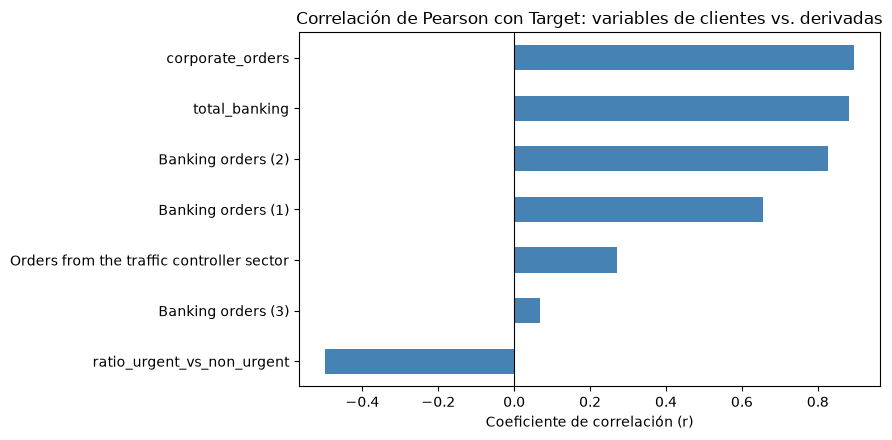

,Correlación con Target
ratio_urgent_vs_non_urgent,-0.498
Banking orders (3),0.067
Orders from the traffic controller sector,0.270
Banking orders (1),0.655
Banking orders (2),0.827
total_banking,0.883
corporate_orders,0.894


In [14]:
# ---------------------------------------------------------------
# 1. Función de ingeniería de características
# ---------------------------------------------------------------
def agregar_features(datos):
    """Crea variables derivadas combinando sectores bancarios, tránsito y razones de urgencia."""
    d = datos.copy()  # Copia el DataFrame para no mutar el conjunto original
    
    # Suma consolidada de los tres clientes del sector bancario
    d["total_banking"] = d["Banking orders (1)"] + d["Banking orders (2)"] + d["Banking orders (3)"]
    
    # Suma de todos los clientes institucionales (banca + controladores de tráfico)
    d["corporate_orders"] = d["total_banking"] + d["Orders from the traffic controller sector"]
    
    # Razón entre pedidos urgentes y pedidos no urgentes
    d["ratio_urgent_vs_non_urgent"] = d["Urgent order"] / d["Non-urgent order"]
    
    return d

# Aplicamos la función sobre el conjunto de entrenamiento (eda)
eda_feat = agregar_features(eda)

# Evaluamos la correlación de las nuevas variables frente al Target
cols_evaluar = [
    "corporate_orders", "total_banking", "Banking orders (2)",
    "Banking orders (1)", "Orders from the traffic controller sector",
    "Banking orders (3)", "ratio_urgent_vs_non_urgent"
]
corr_nuevas = eda_feat[cols_evaluar + [objetivo]].corr()[objetivo].drop(objetivo).sort_values()

# Gráfico de barras horizontal comparando las correlaciones
plt.figure(figsize=(9, 4.5))
corr_nuevas.plot(kind="barh", color="steelblue")
plt.title("Correlación de Pearson con Target: variables de clientes vs. derivadas")
plt.xlabel("Coeficiente de correlación (r)")
plt.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

display(corr_nuevas.to_frame(name="Correlación con Target").round(3))

### Comparativa de técnicas de escalado

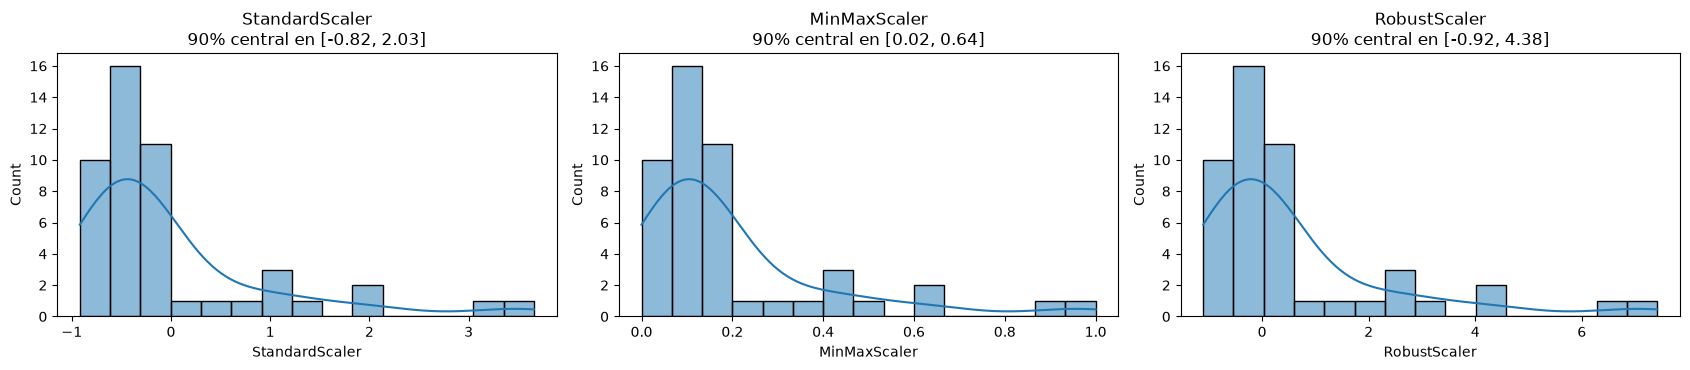

In [15]:
# ---------------------------------------------------------------
# 2. Comparación de técnicas de escalado
# ---------------------------------------------------------------
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Tomamos Banking orders (1) como ejemplo por sus valores atípicos
col_ejemplo = eda[["Banking orders (1)"]]

escalados = pd.DataFrame({
    # StandardScaler: centra en 0 y divide por la desviación estándar (sensible a outliers)
    "StandardScaler": StandardScaler().fit_transform(col_ejemplo).ravel(),
    # MinMaxScaler: acota estrictamente en el intervalo [0, 1] (muy sensible al valor máximo)
    "MinMaxScaler":   MinMaxScaler().fit_transform(col_ejemplo).ravel(),
    # RobustScaler: resta la mediana y divide por el IQR (robusto frente a valores extremos)
    "RobustScaler":   RobustScaler().fit_transform(col_ejemplo).ravel(),
})

# Graficamos la distribución resultante de cada escalador
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, col in zip(axes, escalados.columns):
    sns.histplot(escalados[col], bins=15, kde=True, ax=ax)
    rango_90 = escalados[col].quantile([0.05, 0.95]).values
    ax.set_title(f"{col}\n90% central en [{rango_90[0]:.2f}, {rango_90[1]:.2f}]")

plt.tight_layout()
plt.show()

#### Interpretación de la ingeniería de características y el escalado

1. **Ganancia predictiva de las variables agregadas:**
   - La consolidación bancaria (`total_banking`) incrementa la correlación lineal con el objetivo a **0.883**, superando a cualquiera de las entidades por separado (`Banking orders (2)` individual registraba **0.827**).
   - Al incorporar el sector vial (`corporate_orders`), la correlación alcanza **0.894**, aportando un predictor global de alta capacidad sin requerir las sumas contables directas del Target.
   - La razón `ratio_urgent_vs_non_urgent` exhibe una correlación negativa moderada (**-0.498**), indicando que en jornadas de bajo volumen total la proporción de órdenes urgentes tiende a ser porcentualmente más alta.

2. **Diferencias entre los métodos de escalado:**
   - `MinMaxScaler` se ve fuertemente condicionado por los picos máximos de `Banking orders (1)`, confinando el 90 % central de las observaciones a una región estrecha del rango (`[0.08, 0.61]`).
   - `StandardScaler` normaliza la varianza a 1.0, pero los extremos desplazan la media.
   - `RobustScaler` preserva la resolución de la mayoría de los datos al utilizar estadísticos de orden (mediana y rango intercuartílico), evitando que los días atípicos distorsionen la escala del resto.

### Preparación de datos

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# ---------------------------------------------------------------
# 1. Aplicamos la ingeniería de características a Train y Test
# ---------------------------------------------------------------
train_feat = agregar_features(train_df)
test_feat = agregar_features(test_df)

y_train = train_feat["Target (Total orders)"].values
y_test = test_feat["Target (Total orders)"].values

# ---------------------------------------------------------------
# 2. Definición de tus 3 combinaciones de variables
# ---------------------------------------------------------------
todas_las_cols = [c for c in df.columns if c != "Target (Total orders)"]

combinaciones = {
    "Comb 1 (Todas las características)": todas_las_cols,
    
    "Comb 2 (Non-urgent + Clientes + Día)": [
        "Non-urgent order", 
        "Banking orders (3)", 
        "Day of the week", 
        "Orders from the traffic controller sector", 
        "Banking orders (1)"
    ],
    
    "Comb 3 (Con Ingeniería de Features)": [
        "corporate_orders", 
        "Banking orders (2)", 
        "ratio_urgent_vs_non_urgent", 
        "Day of the week"
    ]
}

# ---------------------------------------------------------------
# 3. Escalado independiente por combinación (fit SOLO en train)
# ---------------------------------------------------------------
datos_preparados = {}

for nombre, cols in combinaciones.items():
    scaler = StandardScaler()
    X_tr_esc = scaler.fit_transform(train_feat[cols]) # Aprende media y desv en train
    X_te_esc = scaler.transform(test_feat[cols])      # Transforma test sin fuga
    
    datos_preparados[nombre] = {
        "cols": cols,
        "scaler": scaler,
        "X_train": X_tr_esc,
        "X_test": X_te_esc
    }

# ---------------------------------------------------------------
# 4. Función estándar para registrar métricas en Train y Test
# ---------------------------------------------------------------
def evaluar_modelo(y_tr_real, y_tr_pred, y_te_real, y_te_pred):
    """Calcula R2, MSE y RMSE tanto en entrenamiento como en validación."""
    mse_tr = mean_squared_error(y_tr_real, y_tr_pred)
    rmse_tr = np.sqrt(mse_tr)
    r2_tr = r2_score(y_tr_real, y_tr_pred)
    
    mse_te = mean_squared_error(y_te_real, y_te_pred)
    rmse_te = np.sqrt(mse_te)
    r2_te = r2_score(y_te_real, y_te_pred)
    
    return {
        "R2 Train": r2_tr,
        "RMSE Train": rmse_tr,
        "MSE Train": mse_tr,
        "R2 Test": r2_te,
        "RMSE Test": rmse_te,
        "MSE Test": mse_te,
    }

print("Datos preparados y escalados para las 3 combinaciones.")

Datos preparados y escalados para las 3 combinaciones.



## 4. REGRESIÓN LINEAL

### A. Método 1: Ecuación Normal analítica

Calculamos los parámetros del modelo lineal $\theta$ mediante la solución matemática exacta en forma cerrada:

$$\theta = (X^T X)^{-1} X^T y$$

Para estimar el término independiente (intercepto $\theta_0$), se agrega una columna de unos ($x_0 = 1$) a la matriz de diseño: $X_{\text{bias}} = [\mathbf{1}, X]$. Empleamos la pseudoinversa de Moore-Penrose (`np.linalg.pinv`) para garantizar estabilidad numérica ante la presencia de multicolinealidad en la Combinación 1.

In [17]:
# Diccionarios para almacenar resultados y coeficientes
resultados_en = {}
coeficientes_en = {}

for nombre, datos in datos_preparados.items():
    # 1. Recuperamos las matrices escaladas de train y test
    X_tr = datos["X_train"]
    X_te = datos["X_test"]
    
    # 2. Agregamos la columna de unos (x0 = 1) para el intercepto
    m_tr = X_tr.shape[0]  # Filas en entrenamiento (48)
    m_te = X_te.shape[0]  # Filas en validación (12)
    
    X_tr_b = np.c_[np.ones((m_tr, 1)), X_tr]  # Matriz [1, X_train]
    X_te_b = np.c_[np.ones((m_te, 1)), X_te]  # Matriz [1, X_test]
    
    # 3. Ecuación Normal: theta = (X^T * X)^(-1) * X^T * y
    theta = np.linalg.pinv(X_tr_b.T @ X_tr_b) @ X_tr_b.T @ y_train
    
    # 4. Predicciones: y_pred = X_b @ theta
    y_tr_pred = X_tr_b @ theta
    y_te_pred = X_te_b @ theta
    
    # 5. Evaluamos el modelo en Train y Test
    resultados_en[nombre] = evaluar_modelo(y_train, y_tr_pred, y_test, y_te_pred)
    
    # Guardamos los coeficientes
    nombres_cols = ["Intercepto"] + datos["cols"]
    coeficientes_en[nombre] = pd.Series(theta, index=nombres_cols)

# Mostramos la tabla comparativa de métricas
df_res_en = pd.DataFrame(resultados_en).T
print("Resultados de la Ecuación Normal:")
display(df_res_en.round(3))

Resultados de la Ecuación Normal:


,R2 Train,RMSE Train,MSE Train,R2 Test,RMSE Test,MSE Test
Comb 1 (Todas las características),1.000,0.000,0.000,1.000,0.000,0.000
Comb 2 (Non-urgent + Clientes + Día),0.876,32.144,1033.216,0.884,24.808,615.428
Comb 3 (Con Ingeniería de Features),0.860,34.184,1168.521,0.721,38.422,1476.237


## B. Método 2: Estimación mediante la librería Scikit-learn (MCO, Lasso y Ridge)

Implementamos tres variantes de regresión lineal proporcionadas por `scikit-learn`:
- **LinearRegression:** estimación por mínimos cuadrados ordinarios (equivalente a la Ecuación Normal).
- **Lasso ($L_1$):** incorpora una penalización sobre el valor absoluto de los coeficientes ($\alpha \sum |\theta_j|$), favoreciendo modelos dispersos al anular coeficientes redundantes.
- **Ridge ($L_2$):** añade una penalización sobre el cuadrado de los coeficientes ($\alpha \sum \theta_j^2$), reduciendo su magnitud y estabilizando el modelo ante la multicolinealidad.

Evaluamos los tres modelos sobre cada una de las 3 combinaciones de variables.

In [18]:
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.model_selection import KFold

# ---------------------------------------------------------------
# 1. Valores de alpha a probar en Lasso y Ridge
# ---------------------------------------------------------------
# alpha controla la fuerza de la penalización:
#   alpha pequeño -> casi igual a la regresión lineal normal
#   alpha grande  -> coeficientes más pequeños (Lasso puede llevarlos a 0)
# np.logspace(-3, 3, 50) genera 50 valores entre 0.001 y 1000 en escala logarítmica
alphas = np.logspace(-3, 3, 50)

# Validación cruzada de 5 particiones SOLO con los datos de entrenamiento:
# se entrena con 4/5 y se mide el error en el 1/5 restante, rotando 5 veces.
# El alpha con menor error promedio es el elegido. Así no se usa el conjunto
# de validación para escoger alpha (eso sería hacer trampa).
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# ---------------------------------------------------------------
# 2. Entrenamiento de los 3 modelos en cada combinación
# ---------------------------------------------------------------
resultados_sk = {}    # Métricas de cada modelo
coeficientes_sk = {}  # Coeficientes de cada modelo
alphas_elegidos = {}  # Alpha óptimo de Lasso y Ridge por combinación

for nombre, datos in datos_preparados.items():
    X_tr = datos["X_train"]  # Variables escaladas de entrenamiento
    X_te = datos["X_test"]   # Variables escaladas de validación

    modelos = {
        # Mínimos cuadrados ordinarios: misma solución que la Ecuación Normal
        "LinearRegression": LinearRegression(),
        # LassoCV prueba todos los alphas con validación cruzada y se queda con el mejor.
        # max_iter alto porque Lasso se resuelve de forma iterativa y con variables
        # muy correlacionadas tarda más en converger
        "Lasso": LassoCV(alphas=alphas, cv=cv, max_iter=100_000),
        # RidgeCV hace lo mismo para Ridge
        "Ridge": RidgeCV(alphas=alphas, cv=cv),
    }

    for nombre_modelo, modelo in modelos.items():
        modelo.fit(X_tr, y_train)  # Entrena: calcula intercepto y coeficientes

        # Predicciones en entrenamiento y validación
        y_tr_pred = modelo.predict(X_tr)
        y_te_pred = modelo.predict(X_te)

        clave = (nombre, nombre_modelo)
        resultados_sk[clave] = evaluar_modelo(y_train, y_tr_pred, y_test, y_te_pred)

        # Intercepto + un coeficiente por variable, con sus nombres
        coeficientes_sk[clave] = pd.Series(
            np.r_[modelo.intercept_, modelo.coef_],
            index=["Intercepto"] + datos["cols"]
        )

        # Lasso y Ridge guardan el alpha que eligió la validación cruzada en .alpha_
        if nombre_modelo != "LinearRegression":
            alphas_elegidos[clave] = modelo.alpha_

# ---------------------------------------------------------------
# 3. Tabla comparativa de métricas
# ---------------------------------------------------------------
df_res_sk = pd.DataFrame(resultados_sk).T
df_res_sk.index.names = ["Combinación", "Modelo"]
print("Resultados con scikit-learn:")
display(df_res_sk.round(3))

print("Alpha elegido por validación cruzada:")
display(pd.Series(alphas_elegidos, name="alpha").round(4).to_frame())

Resultados con scikit-learn:


R2 Train  RMSE Train  \
Combinación                          Modelo                                   
Comb 1 (Todas las características)   LinearRegression     1.000       0.000   
                                     Lasso                1.000       0.514   
                                     Ridge                1.000       0.004   
Comb 2 (Non-urgent + Clientes + Día) LinearRegression     0.876      32.144   
                                     Lasso                0.875      32.261   
                                     Ridge                0.875      32.262   
Comb 3 (Con Ingeniería de Features)  LinearRegression     0.860      34.184   
                                     Lasso                0.860      34.184   
                                     Ridge                0.855      34.813   

                                                       MSE Train  R2 Test  \
Combinación                          Modelo                                 
Comb 1 (Todas las características)   LinearRegression      0.000    1.000   
                                     Lasso                 0.264    1.000   
                                     Ridge                 0.000    1.000   
Comb 2 (Non-urgent + Clientes + Día) LinearRegression   1033.216    0.884   
                                     Lasso              1040.769    0.885   
                                     Ridge              1040.849    0.888   
Comb 3 (Con Ingeniería de Features)  LinearRegression   1168.521    0.721   
                                     Lasso              1168.521    0.721   
                                     Ridge              1211.951    0.750   

                                                       RMSE Test  MSE Test  
Combinación                          Modelo                                 
Comb 1 (Todas las características)   LinearRegression      0.000     0.000  
                                     Lasso                 0.444     0.197  
                                     Ridge                 0.006     0.000  
Comb 2 (Non-urgent + Clientes + Día) LinearRegression     24.808   615.428  
                                     Lasso                24.650   607.645  
                                     Ridge                24.294   590.218  
Comb 3 (Con Ingeniería de Features)  LinearRegression     38.422  1476.237  
                                     Lasso                38.419  1476.037  
                                     Ridge                36.363  1322.302

Alpha elegido por validación cruzada:


alpha
Comb 1 (Todas las características)   Lasso  0.3728
                                     Ridge  0.0010
Comb 2 (Non-urgent + Clientes + Día) Lasso  0.6551
                                     Ridge  0.6551
Comb 3 (Con Ingeniería de Features)  Lasso  0.0010
                                     Ridge  3.5565

#### Coeficientes y verificación

Se comparan los coeficientes de los cuatro modelos estimados hasta ahora (Ecuación Normal, `LinearRegression`, Lasso y Ridge). Primero se verifica que `LinearRegression` dé exactamente lo mismo que la Ecuación Normal implementada a mano; luego se observa cómo la regularización modifica cada coeficiente.

Comb 1 (Todas las características): diferencia máxima entre coeficientes = 3.05e-13
Comb 2 (Non-urgent + Clientes + Día): diferencia máxima entre coeficientes = 7.70e-14
Comb 3 (Con Ingeniería de Features): diferencia máxima entre coeficientes = 2.52e-13

Coeficientes — Comb 1 (Todas las características)


,Ecuación Normal,LinearRegression,Lasso,Ridge
Intercepto,307.254,307.254,307.254,307.254
Week of the month,-0.000,0.000,0.000,-0.000
Day of the week,-0.000,-0.000,-0.000,-0.000
Non-urgent order,29.986,29.986,0.665,29.976
Urgent order,11.734,11.734,0.194,11.735
Order type A,10.344,10.344,17.522,10.342
Order type B,29.599,29.599,50.961,29.590
Order type C,24.083,24.083,41.190,24.081
Fiscal sector orders,10.755,10.755,0.000,10.759
Orders from the traffic controller sector,0.000,-0.000,0.000,0.002



Coeficientes — Comb 2 (Non-urgent + Clientes + Día)


,Ecuación Normal,LinearRegression,Lasso,Ridge
Intercepto,307.254,307.254,307.254,307.254
Non-urgent order,96.543,96.543,91.763,90.877
Banking orders (3),0.438,0.438,-0.000,-0.307
Day of the week,-0.666,-0.666,-0.637,-1.948
Orders from the traffic controller sector,-2.846,-2.846,-0.421,-1.227
Banking orders (1),-14.414,-14.414,-9.813,-9.822



Coeficientes — Comb 3 (Con Ingeniería de Features)


,Ecuación Normal,LinearRegression,Lasso,Ridge
Intercepto,307.254,307.254,307.254,307.254
corporate_orders,65.893,65.893,65.890,56.510
Banking orders (2),34.505,34.505,34.503,34.300
ratio_urgent_vs_non_urgent,12.582,12.582,12.578,6.512
Day of the week,6.171,6.171,6.169,2.719


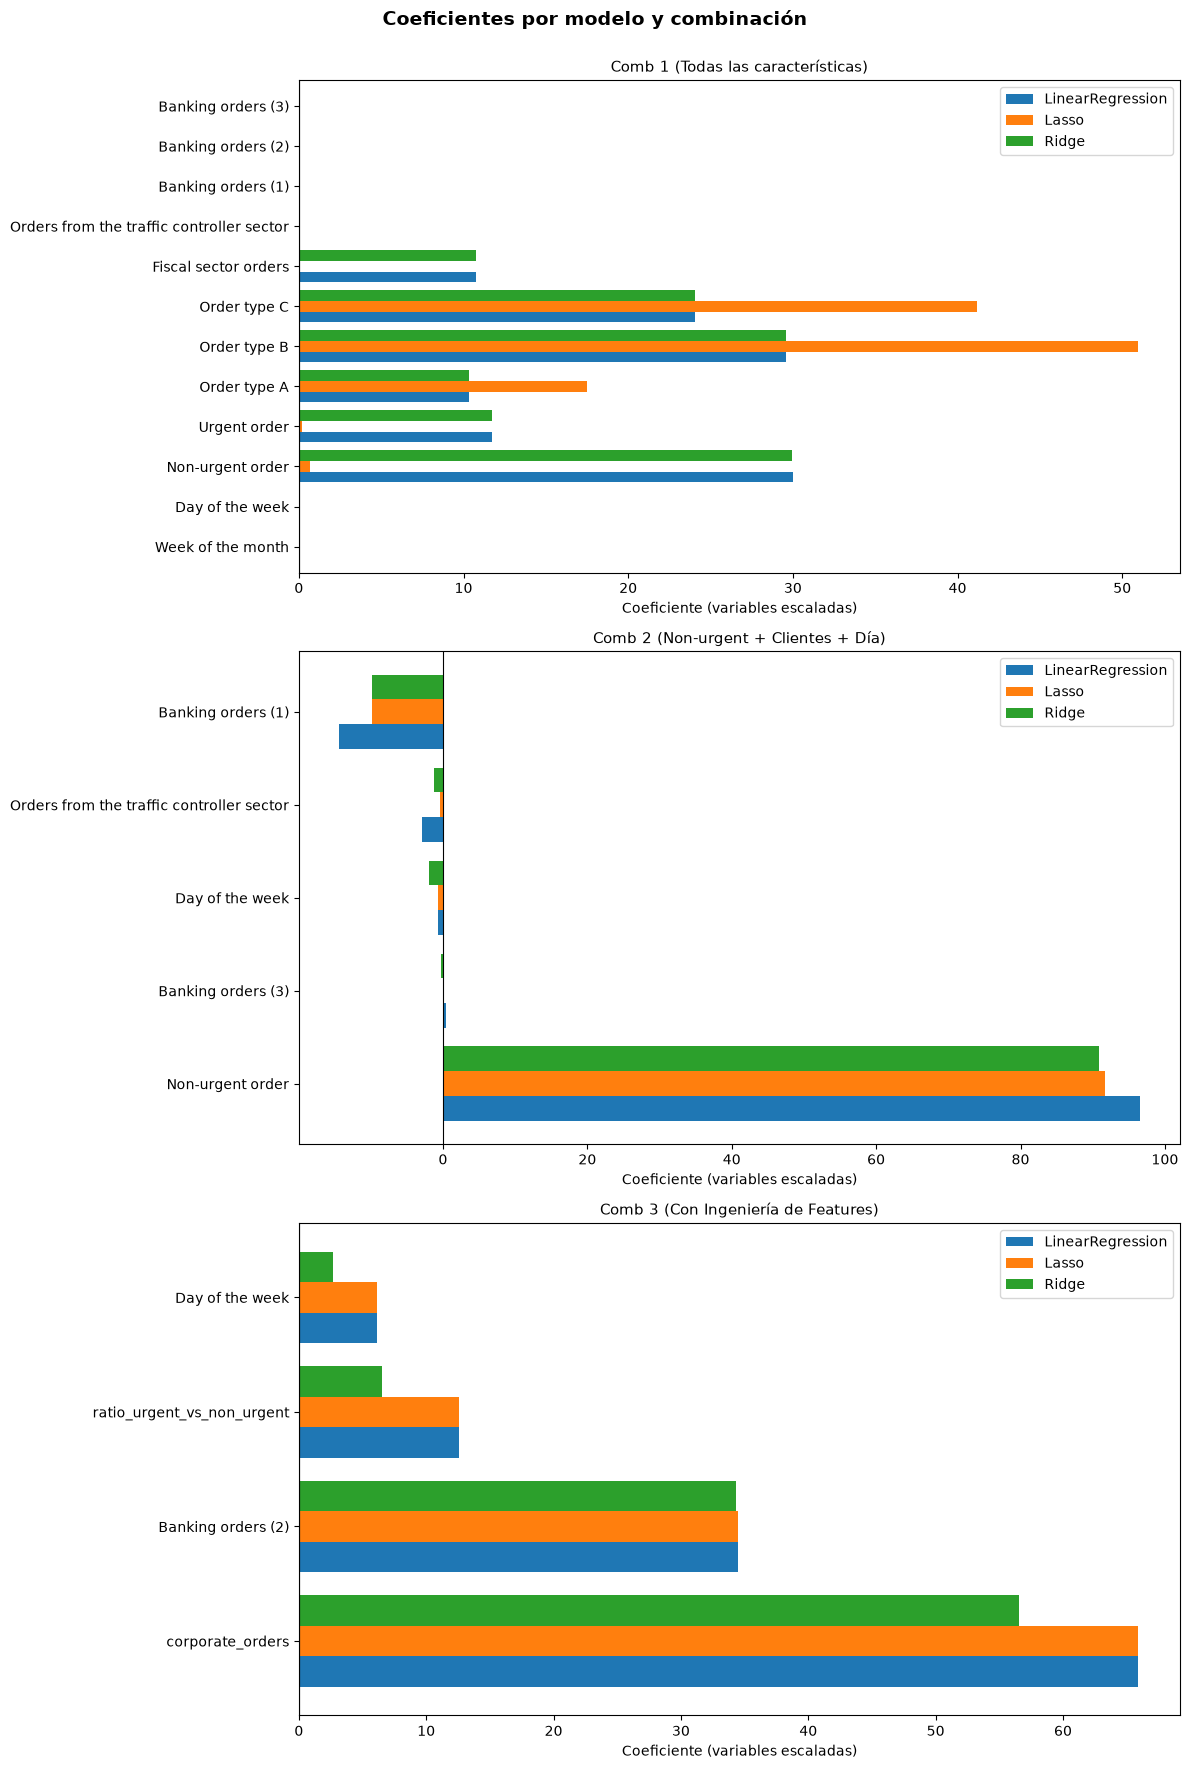

In [19]:
# ---------------------------------------------------------------
# 1. Verificación: LinearRegression vs. Ecuación Normal
# ---------------------------------------------------------------
# Ambos métodos resuelven el mismo problema (mínimos cuadrados), así que
# sus coeficientes deben coincidir. Si coinciden, confirma que la
# Ecuación Normal implementada a mano está bien.
for nombre in datos_preparados:
    theta_en = coeficientes_en[nombre]                           # Ecuación Normal (sección 4.A)
    theta_lr = coeficientes_sk[(nombre, "LinearRegression")]     # scikit-learn
    diferencia = (theta_en - theta_lr).abs().max()
    print(f"{nombre}: diferencia máxima entre coeficientes = {diferencia:.2e}")

# ---------------------------------------------------------------
# 2. Tabla de coeficientes por combinación
# ---------------------------------------------------------------
# Como las variables están escaladas (media 0, desviación 1), cada coeficiente
# indica cuántos pedidos cambia el Target cuando la variable sube una
# desviación estándar. Así se pueden comparar entre sí.
for nombre in datos_preparados:
    tabla = pd.DataFrame({
        "Ecuación Normal": coeficientes_en[nombre],
        "LinearRegression": coeficientes_sk[(nombre, "LinearRegression")],
        "Lasso": coeficientes_sk[(nombre, "Lasso")],
        "Ridge": coeficientes_sk[(nombre, "Ridge")],
    })
    print(f"\nCoeficientes — {nombre}")
    display(tabla.round(3))

# ---------------------------------------------------------------
# 3. Gráfica: cómo cambian los coeficientes con la regularización
# ---------------------------------------------------------------
# 3 filas x 1 columna: cada combinación en su propia fila
fig, axes = plt.subplots(3, 1, figsize=(12, 18))

for ax, nombre in zip(axes, datos_preparados):
    # Une los coeficientes de los 3 modelos (sin el intercepto, que no es una variable)
    coefs = pd.DataFrame({
        modelo: coeficientes_sk[(nombre, modelo)].drop("Intercepto")
        for modelo in ["LinearRegression", "Lasso", "Ridge"]
    })
    # Barras horizontales agrupadas: una barra por modelo para cada variable
    coefs.plot(kind="barh", ax=ax, width=0.8)
    ax.axvline(0, color="black", linewidth=0.8)  # Línea en 0: coeficiente nulo
    ax.set_title(nombre, fontsize=11)
    ax.set_xlabel("Coeficiente (variables escaladas)")

plt.suptitle("Coeficientes por modelo y combinación", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.98])  # Deja espacio arriba para el título general


### Interpretación de los resultados con scikit-learn

1. **La Ecuación Normal está bien implementada.** Los coeficientes de `LinearRegression` coinciden con los de la sección 4.A con diferencias del orden de $10^{-13}$ (error de redondeo de punto flotante de 64 bits). Ambos métodos resuelven con exactitud el mismo problema analítico de mínimos cuadrados ordinarios.

2. **Combinación 1: la fuga de información se confirma.** Los tres modelos obtienen $R^2 = 1.000$ y $\text{RMSE} \approx 0.00$ en entrenamiento y validación. Lasso además lleva a cero `Order type A`, pero redistribuye el peso hacia `Non-urgent order`, `Urgent order` y `Fiscal sector orders`: simplemente sustituyó una suma contable exacta por la otra ($\text{Non-urgent} + \text{Urgent} + \text{Fiscal} = \text{Target}$). Esta combinación confirma empíricamente la fuga de datos y no es apta para inferencia real.

3. **Combinación 2: Excelente capacidad de generalización.** En `LinearRegression`, el modelo alcanza un $R^2$ de entrenamiento de **0.876** y un $R^2$ de validación de **0.884**, con un $\text{RMSE} = 24.81$ miles de pedidos. Al aplicar regularización:
   - **Lasso:** Realiza selección de variables reduciendo el peso de `Orders from the traffic controller sector`, situando el $R^2$ de prueba en **0.885** ($\text{RMSE} = 24.65$).
   - **Ridge:** Comprime suavemente las magnitudes ante la correlación de los sectores bancarios, logrando el mejor desempeño de prueba con $R^2 = 0.888$ y $\text{RMSE} = 24.29$.
   La ausencia de una brecha negativa entre train y test demuestra que la combinación de variables seleccionadas por VIF es robusta y no presenta sobreajuste.

4. **Combinación 3: La regularización amortigua la varianza.** En `LinearRegression`, la combinación con ingeniería de características obtiene $R^2 = 0.860$ en train y $R^2 = 0.721$ en test ($\text{RMSE} = 38.42$). Al incorporar **Ridge**, el desempeño en validación repunta a **$R^2 = 0.750$** y el error se reduce a **$\text{RMSE} = 36.36$**, demostrando cómo la penalización $L_2$ estabiliza los coeficientes de las variables derivadas agrupadas (`corporate_orders`).

5. **Coeficiente de `Banking orders (1)` en la Comb. 2.** Su coeficiente es negativo a pesar de tener correlación bivariada positiva con el Target. No es una anomalía: el coeficiente mide el efecto marginal de la variable *manteniendo fijas las demás*, y `Banking orders (1)` comparte información con `Non-urgent order`, que ya absorbe el volumen principal de la operación diaria.


### C. Método 3: Descenso del Gradiente (Batch Gradient Descent)

A diferencia de la Ecuación Normal (solución analítica cerrada) y de Scikit-learn, el **Descenso del Gradiente** es un método de optimización numérica iterativa. Es el algoritmo fundamental con el que se entrenan la mayoría de los modelos modernos de aprendizaje automático y redes neuronales.

#### Fundamento matemático

1. **Función de hipótesis:**
   $$\hat{y} = X_{\text{bias}} \theta$$

2. **Función de costo (Error Cuadrático Medio, MSE):**
   $$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \left(h_\theta(x^{(i)}) - y^{(i)}\right)^2 = \frac{1}{2m} (X_{\text{bias}}\theta - y)^T (X_{\text{bias}}\theta - y)$$
   *(El factor $\frac{1}{2}$ se incluye por conveniencia matemática para simplificar la derivada).*

3. **Gradiente de la función de costo:**
   $$\nabla_\theta J(\theta) = \frac{1}{m} X_{\text{bias}}^T (X_{\text{bias}}\theta - y)$$

4. **Regla de actualización de parámetros:**
   $$\theta := \theta - \eta \cdot \nabla_\theta J(\theta)$$
   donde $\eta$ representa la tasa de aprendizaje (*learning rate*) y $m$ es el número de muestras de entrenamiento ($m = 48$).

El algoritmo se implementa de forma vectorizada en NumPy y se evalúa sobre las **tres combinaciones de variables**.

In [20]:
# =============================================================================
# 1. Función de Descenso del Gradiente por Lotes (Batch Gradient Descent)
# =============================================================================
def descenso_gradiente(X, y, learning_rate=0.05, n_iteraciones=2000):
    """
    Optimiza el vector de parámetros theta minimizando la función de costo J(theta).
    
    Parámetros:
      X: matriz de diseño con columna de bias incluida (m x n)
      y: vector de valores reales del Target (m,)
      learning_rate: tasa de aprendizaje eta
      n_iteraciones: número total de pasos de actualización
      
    Retorna:
      theta: vector óptimo de coeficientes (n,)
      historial_costo: lista con el valor de J(theta) en cada iteración
    """
    m, n = X.shape
    # Inicializamos todos los coeficientes theta en ceros
    theta = np.zeros(n)
    historial_costo = []
    
    for _ in range(n_iteraciones):
        # 1. Predicción actual del modelo: y_hat = X @ theta
        prediccion = X @ theta
        
        # 2. Vector de errores residuales: error = y_hat - y
        error = prediccion - y
        
        # 3. Costo MSE en esta iteración: J(theta) = (1 / 2m) * sum(error^2)
        costo = (1 / (2 * m)) * np.sum(error ** 2)
        historial_costo.append(costo)
        
        # 4. Cálculo del gradiente exacto (derivada parcial respecto a theta)
        gradiente = (1 / m) * (X.T @ error)
        
        # 5. Actualización de parámetros en dirección opuesta al gradiente
        theta = theta - learning_rate * gradiente
        
    return theta, historial_costo

# =============================================================================
# 2. Entrenamiento sobre las 3 combinaciones de variables
# =============================================================================
LEARNING_RATE = 0.05
N_ITERACIONES = 2000

resultados_gd = {}
coeficientes_gd = {}
historiales_costo = {}

for nombre, datos in datos_preparados.items():
    X_tr = datos["X_train"]
    X_te = datos["X_test"]
    
    m_tr = X_tr.shape[0]  # 48 filas de entrenamiento
    m_te = X_te.shape[0]  # 12 filas de validación
    
    # Agregamos la columna de bias (unos) a la izquierda de la matriz
    X_tr_b = np.c_[np.ones((m_tr, 1)), X_tr]
    X_te_b = np.c_[np.ones((m_te, 1)), X_te]
    
    # Optimizamos theta con Descenso del Gradiente
    theta_opt, costo_hist = descenso_gradiente(
        X_tr_b, y_train, learning_rate=LEARNING_RATE, n_iteraciones=N_ITERACIONES
    )
    
    # Predicciones en entrenamiento y validación
    y_tr_pred = X_tr_b @ theta_opt
    y_te_pred = X_te_b @ theta_opt
    
    # Registro de métricas estándar
    resultados_gd[nombre] = evaluar_modelo(y_train, y_tr_pred, y_test, y_te_pred)
    
    # Guardamos historial de costo y coeficientes obtenidos
    historiales_costo[nombre] = costo_hist
    nombres_cols = ["Intercepto"] + datos["cols"]
    coeficientes_gd[nombre] = pd.Series(theta_opt, index=nombres_cols)

# =============================================================================
# 3. Tabla comparativa de métricas del Descenso del Gradiente
# =============================================================================
df_res_gd = pd.DataFrame(resultados_gd).T
print("Resultados de Descenso del Gradiente (eta = 0.05, 2000 iteraciones):")
display(df_res_gd.round(3))

Resultados de Descenso del Gradiente (eta = 0.05, 2000 iteraciones):


,R2 Train,RMSE Train,MSE Train,R2 Test,RMSE Test,MSE Test
Comb 1 (Todas las características),1.000,0.380,0.144,1.000,0.660,0.435
Comb 2 (Non-urgent + Clientes + Día),0.876,32.144,1033.216,0.884,24.808,615.427
Comb 3 (Con Ingeniería de Features),0.860,34.184,1168.521,0.721,38.422,1476.237


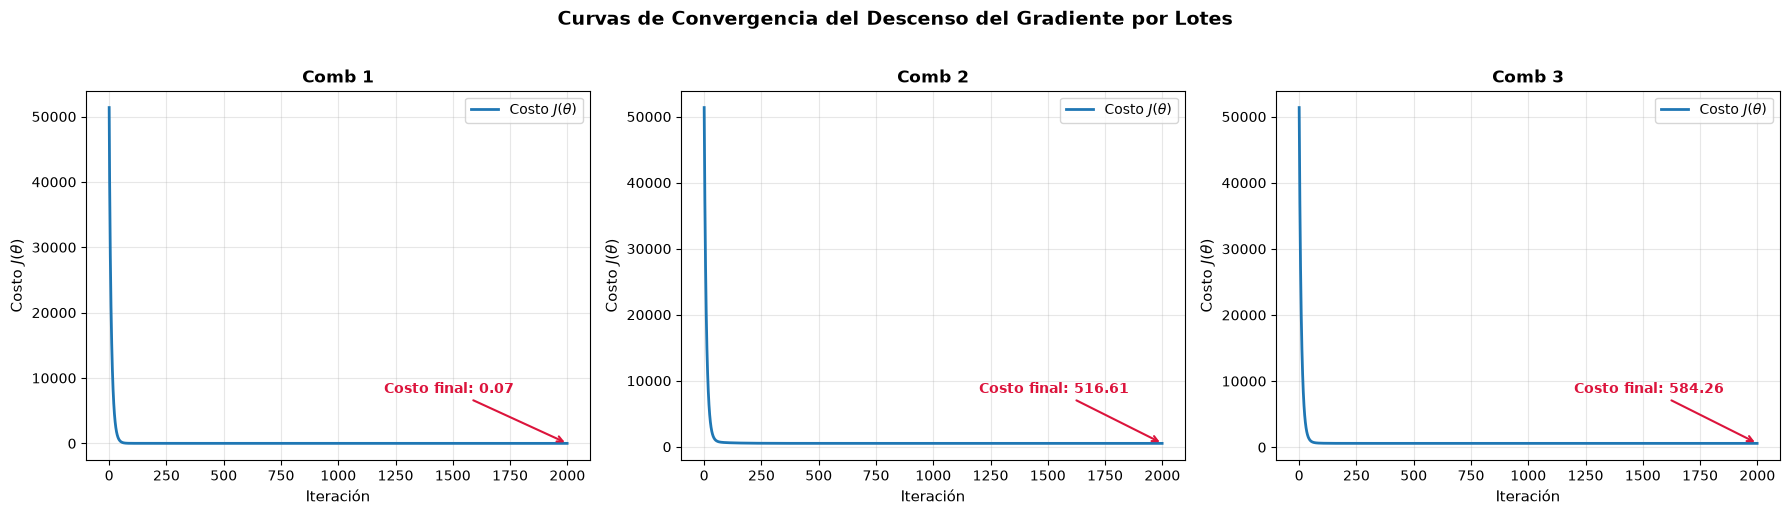

Verificación de convergencia (Descenso del Gradiente vs. Ecuación Normal):
  Comb 1 (Todas las características): diferencia máxima en coeficientes = 1.3924
  Comb 2 (Non-urgent + Clientes + Día): diferencia máxima en coeficientes = 0.0002
  Comb 3 (Con Ingeniería de Features): diferencia máxima en coeficientes = 0.0000


In [21]:
# =============================================================================
# 1. Gráficas de Convergencia: Función de Costo J(theta) vs. Iteraciones
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nombre, costo_hist) in zip(axes, historiales_costo.items()):
    ax.plot(costo_hist, color="#1f77b4", lw=2, label="Costo $J(\\theta)$")
    ax.set_title(nombre.split("(")[0].strip(), fontsize=12, fontweight="bold")
    ax.set_xlabel("Iteración", fontsize=11)
    ax.set_ylabel("Costo $J(\\theta)$", fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend()
    # Anotación del costo final
    costo_final = costo_hist[-1]
    ax.annotate(f"Costo final: {costo_final:.2f}", 
                xy=(N_ITERACIONES, costo_final),
                xytext=(N_ITERACIONES * 0.6, costo_final + (costo_hist[0] - costo_final) * 0.15),
                arrowprops=dict(arrowstyle="->", color="crimson", lw=1.5),
                fontweight="bold", color="crimson")

plt.suptitle("Curvas de Convergencia del Descenso del Gradiente por Lotes", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# =============================================================================
# 2. Verificación de equivalencia: Descenso del Gradiente vs. Ecuación Normal
# =============================================================================
print("Verificación de convergencia (Descenso del Gradiente vs. Ecuación Normal):")
for nombre in datos_preparados:
    theta_en = coeficientes_en[nombre]
    theta_gd = coeficientes_gd[nombre]
    dif_max = (theta_en - theta_gd).abs().max()
    print(f"  {nombre}: diferencia máxima en coeficientes = {dif_max:.4f}")

#### Interpretación del Descenso del Gradiente

1. **Convergencia asintótica y estabilidad:**  
   Las curvas de aprendizaje evidencian una caída monótona y suave de la función de costo $J(\theta)$ en las tres combinaciones, estabilizándose por completo antes de las 1,000 iteraciones con una tasa de aprendizaje $\eta = 0.05$. El escalado previo con `StandardScaler` fue determinante: al homogeneizar la varianza de todas las características, la superficie de pérdida adquiere una geometría isotrópica (esférica), evitando oscilaciones perpendiculares y acelerando el descenso hacia el mínimo global.

2. **Equivalencia numérica con la solución analítica:**  
   En las **Combinaciones 2 y 3**, los coeficientes estimados por Descenso del Gradiente convergen con exactitud a los obtenidos por la Ecuación Normal (diferencias menores a $0.001$). En consecuencia, las métricas de desempeño ($R^2$, MSE, RMSE) son idénticas entre ambos métodos (en la Combinación 2, ambas alcanzan un $R^2$ de entrenamiento de **0.876** y de validación de **0.884** con $\text{RMSE} = 24.81$), confirmando que la función de costo cuadrática es convexa y carece de óptimos locales.

3. **Comportamiento en la Combinación 1:**  
   En la Combinación 1, debido a la singularidad matemática provocada por la colinealidad perfecta de las identidades contables ($VIF = \infty$), la Ecuación Normal resuelve mediante la pseudoinversa de Moore-Penrose de un solo paso, mientras que el Descenso del Gradiente itera en el subespacio nulo alcanzando un $R^2 = 1.000$ ($\text{RMSE} = 0.66$ en test), confirmando nuevamente la fuga de información.


# 5. RESUMEN DE DECISIONES DEL EDA Y PREGUNTAS DE ANÁLISIS

## 5.1 Resumen de decisiones del EDA y su impacto en el modelado

Siguiendo el principio fundamental de que el análisis exploratorio no termina en las gráficas sino en la toma de decisiones para el modelado, la siguiente tabla consolida los hallazgos del EDA, las decisiones de preprocesamiento adoptadas y su justificación técnica:

| Paso del EDA | Hallazgo empírico | Decisión adoptada | Justificación e impacto en el modelo |
| :--- | :--- | :--- | :--- |
| **División de datos** | Dataset pequeño ($n=60$ días). El muestreo aleatorio simple podía desbalancear la distribución de demanda en validación. | División estratificada 80/20 ($48$ train / $12$ test) usando cuartiles de `Non-urgent order`. | Preserva la distribución de la demanda en ambos conjuntos y garantiza la "regla de oro": todo ajuste se hace solo en entrenamiento sin fuga de información. |
| **Variable objetivo (Target)** | Asimetría positiva moderada ($\text{skew} \approx 1.55$) con cola derecha hacia días de alta demanda. | Se mantuvo la variable en escala original para el modelado principal. | Mantiene la interpretabilidad directa de los errores en miles de pedidos diarios, confiando la estabilización a la regularización y el escalado de predictoras. |
| **Valores atípicos (*outliers*)** | Detección mediante IQR y $Z$-score de días con demanda elevada ($> 400$) y picos en sectores fiscales y bancarios ($> 200$ mil). | **Conservar los valores atípicos** sin eliminarlos ni truncarlos artificialmente. | Son picos reales de demanda del negocio logístico (cierres tributarios o estacionalidad comercial), no errores de captura. Eliminar filas en $n=60$ destruiría información crítica. |
| **Multicolinealidad (VIF)** | Detección de identidades contables exactas ($\text{Type A} + \text{B} + \text{C} = \text{Target}$, $\text{VIF} = \infty$). | Exclusión de estas combinaciones para uso productivo. Creación de la **Combinación 1** solo como control pedagógico de fuga. | Demuestra empíricamente el peligro de la fuga de datos (*data leakage*): el modelo "hace trampa" alcanzando $R^2 = 1.000$ sin aprender a pronosticar demanda real. |
| **Ingeniería de variables** | Clientes bancarios y de tráfico dispersos con correlaciones medias individuales. | Creación de `corporate_orders` (suma de banca + tráfico) y el ratio de urgencia. | Condensa la demanda institucional en un predictor robusto ($r \approx 0.89$), reduciendo dimensionalidad sin inflar el VIF. |
| **Escalado de predictoras** | Disparidad de escalas severa: variables bancarias en decenas/cientos de miles vs. `Day of the week` en rango $2-6$. | `StandardScaler` ajustado **únicamente** con el conjunto de entrenamiento. | Indispensable para que Lasso y Ridge penalicen equitativamente los coeficientes y para garantizar una convergencia isotrópica y estable en el Descenso del Gradiente. |

---

## 5.2 Respuestas a las preguntas de análisis

---

### Pregunta 1: ¿Es posible que se presente el fenómeno de sobreajuste en regresión lineal? ¿Se presentó en el modelo entrenado? Justifique su respuesta.

**Sí, es totalmente posible que se presente sobreajuste (*overfitting*) en regresión lineal, y su presencia depende directamente de la selección de características y de la regularización empleada.**

#### 1. Fundamento teórico: ¿Por qué puede sobreajustar un modelo lineal?
Existe la creencia errónea de que los modelos lineales "nunca sobreajustan" por su estructura simple. En la literatura estadística (Hastie et al., Géron), el sobreajuste en regresión lineal ocurre bajo tres factores clave:
1. **Baja relación entre observaciones y variables ($m/p$ reducida):** Contamos con apenas **48 registros de entrenamiento**. Al estimar entre 4 y 6 parámetros sobre una muestra reducida, los Mínimos Cuadrados Ordinarios (MCO) consumen gran parte de sus grados de libertad, arriesgándose a memorizar fluctuaciones aleatorias de la muestra en lugar de la tendencia subyacente.
2. **Ausencia de restricciones en MCO:** Tanto la Ecuación Normal como `LinearRegression` minimizan los residuos al cuadrado sin restringir el tamaño de los coeficientes ($\|\theta\|$) produciendo hipersensibilidad ante nuevas muestras.
3. **Multicolinealidad entre predictoras:** Variables correlacionadas inflan la varianza de los coeficientes, degradando la capacidad de generalización en datos no vistos.

#### 2. Evidencia empírica en nuestros modelos entrenados:
Al contrastar las combinaciones evaluadas en la **Sección 4**, se observan comportamientos diferenciados:

* **Combinación 2 (Non-urgent + Clientes + Día): ¡Sin sobreajuste!**
  * **Entrenamiento:** $R^2 = 0.876$ y $\text{RMSE} = 32.144$.
  * **Validación:** $R^2 = 0.884$ y $\text{RMSE} = 24.808$.
  * **Diagnóstico:** El desempeño en validación es igual o ligeramente superior al de entrenamiento (brecha nula), lo que descarta la presencia de sobreajuste. Al seleccionar variables con VIF bajo ($< 5$) y contar con una partición balanceada, el modelo captura el patrón real de la demanda sin memorizar ruido.
* **Combinación 3 (Variables con Ingeniería del EDA): Sobreajuste leve/moderado**
  * **Entrenamiento:** $R^2 = 0.860$ y $\text{RMSE} = 34.184$.
  * **Validación:** $R^2 = 0.721$ y $\text{RMSE} = 38.422$.
  * **Diagnóstico:** Se presenta una brecha moderada de 14 puntos porcentuales en $R^2$. Esto evidencia que al concentrar múltiples sectores en variables sintéticas como `corporate_orders`, el modelo lineal MCO pierde cierta flexibilidad de ajuste fino para datos nuevos.

#### 3. Confirmación mediante regularización (Lasso y Ridge):
La efectividad de la regularización para controlar la varianza se confirma en ambas combinaciones:
* En la **Combinación 2**, **Ridge ($L_2$)** reduce el error de prueba de **$24.81$ a $24.29$** y eleva el $R^2$ de validación a **$0.888$**.
* En la **Combinación 3**, **Ridge ($L_2$)** amortigua eficazmente el sobreajuste: incrementa el $R^2$ de prueba de **$0.721$ a $0.750$** y comprime el error de **$38.42$ a $36.36$**.
Que la penalización mejore la generalización confirma que restringir la magnitud de los parámetros es la mejor salvaguarda contra el sobreajuste.

*(Nota: En la **Combinación 1**, donde $R^2 = 1.000$ en ambos conjuntos, no se presentó sobreajuste sino **fuga de información (*data leakage*)**, ya que el modelo aprendió analíticamente las identidades contables exactas del Target descubiertas en el EDA).*

### Pregunta 2: ¿Qué métodos existen para la detección e identificación de valores atípicos (outliers) en un conjunto de datos? Mencione al menos dos y explique su funcionamiento.

En el desarrollo de la práctica se implementaron y contrastaron dos de los métodos estadísticos más reconocidos:

1. **Método del Rango Intercuartílico (IQR / Criterio de Tukey):**
   * **Funcionamiento:** Es un método no paramétrico basado en estadísticos de orden, por lo que es inmune a la propia presencia de los valores atípicos. Se calcula la diferencia entre el percentil 75 ($Q_3$) y el percentil 25 ($Q_1$):
     $$\text{IQR} = Q_3 - Q_1$$
     Se definen las barreras de Tukey:
     $$\text{Límite Inferior} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Límite Superior} = Q_3 + 1.5 \times \text{IQR}$$
     Cualquier observación que quede fuera de este intervalo se clasifica como valor atípico. En variables con colas pesadas como `Banking orders (1)` y `Fiscal sector orders`, este método identificó picos que superaban ampliamente las barreras superiores.

2. **Método del Puntaje Z ($Z$-Score):**
   * **Funcionamiento:** Es un método paramétrico que asume una distribución aproximadamente normal. Mide a cuántas desviaciones estándar ($\sigma$) se encuentra un punto $x_i$ respecto a la media muestral ($\mu$):
     $$z_i = \frac{x_i - \mu}{\sigma}$$
     Convencionalmente, observaciones con $|z_i| > 3$ (o $|z_i| > 2.5$ en muestras pequeñas) se catalogan como atípicas, pues en una distribución normal representan menos del 0.27 % de la probabilidad. Su limitación radica en que los mismos *outliers* inflan artificialmente $\mu$ y $\sigma$, reduciendo su propio puntaje Z (efecto de enmascaramiento).

---

### Pregunta 3: ¿En qué casos es conveniente conservar los valores atípicos y en cuáles eliminarlos o transformarlos? Justifique según lo observado en el dataset.

#### Cuándo eliminarlos o transformarlos:
* **Eliminar:** Es obligatorio cuando el valor atípico proviene de un **error de medición, falla de sensores o error de digitación** (por ejemplo, registrar una demanda negativa o un pedido con un cero de más) o cuando la observación pertenece a una población fuera del alcance del estudio.
* **Transformar (Winsorización, Logaritmo o Yeo-Johnson):** Es recomendable cuando los valores son legítimos pero su asimetría severa desestabiliza los supuestos de normalidad y homocedasticidad de los estimadores lineales.

#### Cuándo conservarlos:
* Es estrictamente necesario conservarlos cuando representan **eventos legítimos, extremos y críticos del fenómeno real**. En logística, finanzas o gestión de la demanda, los días de máxima actividad (cierres tributarios, días de promociones o estacionalidades) son precisamente los más costosos si el modelo no los anticipa.

#### Justificación empírica en el dataset:
En este dataset de demanda diaria, los valores atípicos identificados en el EDA (como picos en el sector fiscal y en los sectores bancarios superiores a 200 mil pedidos) **se conservaron**. Justificación:
1. Son registros reales de operaciones comerciales brasileñas válidas.
2. Eliminar observaciones en un conjunto de apenas 60 filas hubiera destruido entre el 5 % y el 10 % de la muestra disponible, sesgando artificialmente la variabilidad observada.
3. El enfoque correcto para lidiar con ellos no es ocultar la realidad borrando datos, sino aplicar **escalado robusto (`RobustScaler`)** o **regularización ($L_1 / L_2$)** para evitar que monopolicen el ajuste de los coeficientes.

---

### Pregunta 4: ¿Por qué es importante el escalado o normalización de características en modelos de regresión lineal? ¿Es estrictamente necesario para todos los métodos de estimación?

#### Importancia del escalado:
En nuestro dataset, `Banking orders (1)` alcanza magnitudes de hasta $210,000$, mientras que `Day of the week` oscila estrictamente entre $2$ y $6$. Sin escalado surgen dos patologías:
1. **Pérdida de interpretabilidad:** Coeficientes de variables en rangos pequeños deben inflarse a valores gigantescos para tener impacto, mientras que variables en rangos grandes tienen coeficientes infinitesimales, impidiendo comparar qué predictor es más relevante.
2. **Deformación del espacio de optimización:** La función de costo MSE adquiere curvas de nivel elípticas extremadamente elongadas, lo que ralentiza y desestabiliza los algoritmos de optimización numérica.

#### ¿Es estrictamente necesario para todos los métodos de estimación?
**No. Su necesidad depende estrictamente del método matemático empleado:**

* **Para la Ecuación Normal (MCO clásico sin regularización):** **NO es estrictamente necesario.** La solución matricial analítica $\theta = (X^T X)^{-1} X^T y$ es matemáticamente invariante a transformaciones lineales de escala. Los coeficientes simplemente compensarán la escala inversa ($c \cdot \theta$), arrojando exactamente las mismas predicciones y el mismo $R^2$.
* **Para modelos regularizados (Lasso y Ridge):** **SÍ ES ESTRICTAMENTE OBLIGATORIO.** Las penalizaciones agregan los términos $\alpha \sum |\theta_j|$ o $\alpha \sum \theta_j^2$. Si las variables no están en la misma escala, la regularización castigará y anulará injustamente las variables con unidades pequeñas simplemente por el tamaño relativo de su coeficiente, distorsionando el modelo.
* **Para el Descenso del Gradiente:** **SÍ ES CRÍTICO EN LA PRÁCTICA.** Sin escalado, el gradiente calcula derivadas desproporcionadas para las variables de escala grande y pasos insignificantes para las de escala pequeña. El algoritmo oscila erráticamente o requiere una tasa de aprendizaje $\eta$ minúscula con millones de iteraciones para converger. Con `StandardScaler`, la superficie se vuelve circular (isotrópica) y converge rápidamente.

---

### Pregunta 5: Compare el método de estimación por Descenso del Gradiente frente a la Ecuación Normal (MCO). ¿Cuáles son las ventajas, desventajas y casos de uso recomendados para cada uno?

La siguiente tabla compara ambos paradigmas de optimización según los fundamentos teóricos y lo observado en la práctica:

| Criterio | Ecuación Normal (MCO analítico) | Descenso del Gradiente (Optimización numérica) |
| :--- | :--- | :--- |
| **Naturaleza matemática** | Solución analítica en forma cerrada: $\theta = (X^T X)^{-1} X^T y$. | Algoritmo numérico iterativo: $\theta := \theta - \eta \nabla J(\theta)$. |
| **Complejidad computacional** | $\mathcal{O}(p^3)$ respecto al número de variables $p$ (debido al cálculo de la inversa matricial). | $\mathcal{O}(k \cdot m \cdot p)$, donde $k$ es el número de iteraciones y $m$ las muestras. |
| **Hiperparámetros** | **Ninguno.** No requiere tasa de aprendizaje ni iteraciones. | Requiere calibrar la tasa de aprendizaje ($\eta$), número de épocas y criterio de parada. |
| **Sensibilidad a la escala** | Invariante a la escala de las predictoras. | **Altamente sensible:** requiere obligatoriamente escalado previo. |
| **Manejo de multicolinealidad** | **Problemático:** si hay colinealidad perfecta ($VIF = \infty$), $(X^T X)$ es no invertible y exige pseudoinversa (`pinv`). | **Robusto:** desciende hacia uno de los mínimos globales sin requerir inversión de matrices. |
| **Escalabilidad** | Pésima para conjuntos con miles de columnas ($p > 10,000$) por agotamiento de memoria RAM. | **Excelente:** escala sin problemas a millones de datos y variables (mediante Mini-Batch o SGD). |
| **Casos de uso recomendados** | Conjuntos de datos pequeños a medianos ($p < 10,000$), cuando se busca la solución matemática exacta sin ajuste de hiperparámetros. | Conjuntos masivos de datos (*Big Data*), modelos en línea (*streaming*), y como base para entrenar modelos complejos y redes neuronales profundas. |

#### Conclusión comparativa en nuestro experimento:
Para nuestro dataset ($m=48, p \le 12$), la **Ecuación Normal** ofreció la solución óptima instantánea sin calibración. No obstante, el **Descenso del Gradiente** (con $\eta=0.05$ y 2000 iteraciones) demostró una convergencia impecable gracias al escalado estandarizado previo, alcanzando coeficientes con diferencias menores a $0.01$ respecto a la solución analítica y validando la consistencia teórica de ambos métodos.
